# 12 Our Imsil catalog against Park et al. (2026)

Park, S., Lee, J., Hwang, G., Kim, J.H., Jung, J., Ko, Y. (2026). *A mid-crustal earthquake swarm in a stable intraplate region of the southwestern Korean Peninsula: generation processes and seismic implications.* Physics of the Earth and Planetary Interiors 381, 107613 (main text, 13 pages, and supplement, 11 pages, in `../papers/`).

They studied the same swarm with largely the same KMA waveforms. This notebook sets each of their results beside ours, measures the differences, and traces each difference to its cause. Their per-event catalog is not public ("available on request"), so their side of every comparison is the number printed in the paper; the figure or table is named beside each one.

**Two recipes of theirs are re-implemented here so that the comparison is like for like.** Both are used only in this notebook; neither changes our pipeline or catalog.
- **Magnitudes.** The ratio $r$ of 5–20 Hz peak ground displacement between an event and the ML 1.9 reference, then $M = 2.07 + 0.73\log_{10} r$ (their Eq. 3 and Fig. 4e), then a conversion to Mw.
- **Migration.** Onset point = centroid of the first 10 events; onset time = first event; front = 90th percentile of distance in successive groups of 10 events; least-squares fits of $r = vt$ and $r = \sqrt{4\pi D t}$ (their Section 4).

**Sections.**
1. Data and methods side by side.
2. Timing: the four phases, the gaps and the two isolated events.
3. Magnitudes on their scale: replication, then the magnitude–frequency comparison.
4. Why our catalog is about half the size of theirs.
5. Absolute location: epicenter and depth.
6. Geometry: plane, extent and thickness.
7. Migration, measured with their recipe.
8. Focal mechanisms tested against our station amplitudes.
9. Waveform similarity against time (their Fig. 11): a time effect or a distance effect?
10. The b value and the magnitude scale.
11. Comprehensive summary.

In [1]:
import os, sys, glob, time
import numpy as np, pandas as pd
from scipy import stats as sps
os.environ.setdefault('HELVETICA_DIR', '/home/msseo/Download/Helvetica')
DL = '/home/msseo/works/72.2025_Imsil_swarm/DL_detection'
sys.path.insert(0, f'{DL}/pipeline')
import config, plotstyle, sumio  # noqa: F401
import matplotlib.pyplot as plt
import obspy
from obspy import UTCDateTime
from obspy.taup import TauPyModel
from obspy.geodetics import gps2dist_azimuth
pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 120)
fmf = pd.read_csv(f'{DL}/catalogs/fmf_final/imsil_fmf_catalog.csv', parse_dates=['origin']).sort_values('origin').reset_index(drop=True)
rel = pd.read_csv(f'{DL}/catalogs/imsil_fmf_relocated.csv', dtype={'event_id': str}); rel['time'] = pd.to_datetime(rel.origin_time_reloc)
rel['emax'] = rel[['ex95_m', 'ey95_m', 'ez95_m']].max(axis=1)
r25 = pd.read_csv(f'{DL}/catalogs/reference_25m_fmf/DL_reference_25m.csv', dtype={'event_id': str}); r25['time'] = pd.to_datetime(r25.origin_time_reloc)
dlr = pd.read_csv(f'{DL}/catalogs/imsil_dl_relocated.csv', dtype={'event_id': str})
kma = pd.read_csv(f'{DL}/catalogs/imsil_kma24.csv', parse_dates=['origin_time_UTC'])
print(f'FMF catalog {len(fmf)} ({int(fmf.is_reference.sum())} references + {int(fmf.is_new.sum())} new); relocated {len(rel)}; 25 m set {len(r25)}; KMA {len(kma)}')

FMF catalog 235 (28 references + 207 new); relocated 212; 25 m set 101; KMA 24


In [2]:
# Their numbers, typed from the paper. Phase windows are whole minutes (P1 20:02-20:19 means 20:02:00-20:19:59).
PARK_PHASES = pd.DataFrame([
    # phase, start, end, n events, Mw min, Mw max, N(Mw >= 0.5), b, b s.e., rate of Mw >= 0.5 per hour, moment (N m)     [Section 5.2, Figs 6 and 10, Fig. S3]
    ('P1', '2025-11-02 20:02', '2025-11-02 20:19', 136, 0.3, 1.5, 113, 1.79, 0.16, 415, 2.1e12),
    ('P2', '2025-11-02 20:23', '2025-11-02 21:49', 286, 0.3, 2.3, 249, 1.46, 0.09, 174, 1.2e13),
    ('P3', '2025-11-02 21:55', '2025-11-02 23:07', 53, 0.5, 1.7, 49, 1.27, 0.18, 44, 2.5e12),
    ('P4', '2025-11-03 00:19', '2025-11-03 00:54', 22, 0.7, 2.0, 22, 1.17, 0.26, 13, 2.3e12),
], columns=['phase', 'start', 'end', 'n', 'mw_min', 'mw_max', 'n_ge_mc', 'b', 'b_se', 'rate_per_h', 'moment_Nm'])
PARK_PHASES['t0'] = pd.to_datetime(PARK_PHASES.start); PARK_PHASES['t1'] = pd.to_datetime(PARK_PHASES.end) + pd.Timedelta(seconds=59.999)
PARK = dict(n_total=498, n_reported=25, n_new=473, mw_min=0.3, mw_max=2.3, mc=0.5, n_ge_mc=438, b=1.40, b_se=0.07, gr_a=3.33,   # abstract, Fig. 5, Fig. S3c
            stations=60, max_dist_km=80, band_mf=(10, 40), band_amp=(5, 20), win_s=(-0.5, 2.0), c1=2.07, c2=0.73,              # Sections 3-4
            strike=89, dip=89, extent_lateral_km=0.30, extent_vertical_km=0.35, box_m=(350, 100), depth_km=(13.6, 14.0),      # Section 5.3, Fig. 7, Fig. S2
            D_zone={'Z1': 0.50, 'Z2': 0.61, 'Z3': 0.56, 'Z4': 0.45}, v_zone={'Z1': 0.034, 'Z2': 0.044, 'Z3': 0.048, 'Z4': 0.050},  # Fig. 9
            dtcc=dict(band=(10, 40), win=(-0.5, 3.5), cc_min=0.2, n_P=26562, n_S=156587, rms_before=0.149, rms_after=0.004))   # supplement
PARK_T1 = pd.DataFrame([   # Table 1: focal-mechanism events (time UTC, lat, lon, depth km, KMA ML, their Mw, plane 1, plane 2, polarities)
    ('2025-11-02 20:32:36', 35.55023, 127.29583, 13.80, 1.7, 1.4, (91, 69, -22), (189, 69, -158), 12),
    ('2025-11-02 20:38:35', 35.55017, 127.29626, 13.84, 1.9, 2.3, (91, 73, -31), (191, 60, -161), 44),
    ('2025-11-02 21:02:32', 35.55021, 127.29622, 13.76, 1.6, 2.0, (89, 69, -41), (196, 52, -153), 26),   # KMA and their Fig. S4: 21:02:29
    ('2025-11-03 00:35:31', 35.55019, 127.29667, 13.69, 1.6, 2.0, (92, 68, -28), (193, 64, -156), 20),
], columns=['time', 'lat', 'lon', 'depth', 'ML_KMA', 'Mw', 'plane1', 'plane2', 'n_pol']); PARK_T1['time'] = pd.to_datetime(PARK_T1.time)
PARK_RATIO = {'2025-11-02 20:29:40': 0.060, '2025-11-02 20:36:50': 0.079, '2025-11-02 22:22:50': 0.120, '2025-11-03 00:19:19': 0.174}   # Fig. 4a-d
PARK_ISOLATED = {'2025-11-02 19:57:38': 0.6, '2025-11-03 04:23:32': 0.9}   # Section 5.2: ~5 min before P1 (Mw 0.6), ~4 h after P4 (Mw 0.9); times = ours
display(PARK_PHASES.drop(columns=['t0', 't1']))

,phase,start,end,n,mw_min,mw_max,n_ge_mc,b,b_se,rate_per_h,moment_Nm
0,P1,2025-11-02 20:02,2025-11-02 20:19,136,0.3,1.5,113,1.79,0.16,415,2.100000e+12
1,P2,2025-11-02 20:23,2025-11-02 21:49,286,0.3,2.3,249,1.46,0.09,174,1.200000e+13
2,P3,2025-11-02 21:55,2025-11-02 23:07,53,0.5,1.7,49,1.27,0.18,44,2.500000e+12
3,P4,2025-11-03 00:19,2025-11-03 00:54,22,0.7,2.0,22,1.17,0.26,13,2.300000e+12


## 1. Data and methods side by side

| Step | Park et al. (2026) | This study |
|---|---|---|
| Waveforms | 60 KMA + KIGAM stations within 80 km, 100 Hz, 1 Oct – 30 Nov 2025 | KS (KMA) from the MARA mirror, 1 Sep 2025 – 31 Jan 2026 (KIGAM has no 2025 data on MARA) |
| Template matching | **one** template (the ML 1.9), 10–40 Hz, P and S windows of 2.5 s (−0.5 to +2.0 s) on all three components; noise-weighted stack | **28** templates (the 25 m reference events), 5–20 Hz, P 1.5 s on Z, S 2.0 s (N/E, or Z at re-oriented stations), 22 KS stations within 60 km |
| Detection threshold | from the Akaike information criterion on the stacked CC (Hirano et al., 2022), then every detection checked by eye | 10 × MAD of the daily network CC per station-configuration segment, ≥ 4 stations, no CC floor (D23) |
| Absolute location | reference event by joint hypocenter–velocity inversion (Kim et al., 2014) from 53 P / 48 S hand picks at 57 stations, starting from Kim et al. (2011) | HYPOINVERSE on PhaseNet+ picks, Kim & Kim (1983) model |
| Relative location | grid search on slant-stacked CC (22 × 23 × 20 m grid), then hypoDD with 26,562 P and 156,587 S CC times (10–40 Hz, 4 s windows, CC ≥ 0.2) | HypoDD (KCR): catalog times among the 28 references + CC times (5–20 Hz, CC ≥ 0.7), 1,000-replica bootstrap, 25 m rule |
| Magnitude | amplitude ratios to the ML 1.9 (5–20 Hz), $M = 2.07 + 0.73\log r$, then Mw (Sheen et al., 2018) | Sheen (2018) ML engine for events with enough stations (notebook 05); no relative magnitudes yet |
| Mechanisms | P first motions, 4 events (12–44 polarities) | none yet |

"CC" is the normalized cross-correlation coefficient between a template and the continuous record. "MAD" is the median absolute deviation, a robust measure of the spread of the CC trace when no event is present.

In [3]:
def dist_km(lat, lon, lat0=35.5502, lon0=127.2960):
    return np.array([gps2dist_azimuth(lat0, lon0, a, b)[0] / 1000 for a, b in zip(lat, lon)])
mara = pd.read_csv('/home/msseo/works/72.2025_Imsil_swarm/station_table/used_stations_100km.csv'); mara['dist'] = dist_km(mara.Latitude, mara.Longitude)
fst = pd.read_csv(f'{DL}/fmf_aligned/stations_imsil_5_20H.csv')
counts = pd.DataFrame([('Park et al.: KMA + KIGAM within 80 km', PARK['stations']),
                       ('KS on MARA within 60 km', int((mara.dist <= 60).sum())), ('KS on MARA within 80 km', int((mara.dist <= 80).sum())),
                       ('KS on MARA within 100 km', len(mara)), ('Our FMF station set (D11)', len(fst))], columns=['station set', 'stations'])
display(counts)
print(f'Channels in the stack: theirs up to {PARK["stations"]} x 3 components x 2 phases = {PARK["stations"] * 6}; ours up to {len(fst)} stations x (1 P + 2 S) = {len(fst) * 3}')

,station set,stations
0,Park et al.: KMA + KIGAM within 80 km,60
1,KS on MARA within 60 km,23
2,KS on MARA within 80 km,38
3,KS on MARA within 100 km,55
4,Our FMF station set (D11),22


Channels in the stack: theirs up to 60 x 3 components x 2 phases = 360; ours up to 22 stations x (1 P + 2 S) = 66


## 2. Timing: the four phases, the gaps and the two isolated events

Their phases P1–P4 (Fig. 6) are applied to our 235 detections.

In [4]:
def phase_of(t):
    for p in PARK_PHASES.itertuples():
        if p.t0 <= t <= p.t1: return p.phase
    return 'outside'
fmf['phase'] = fmf.origin.apply(phase_of)
rows = []
for p in PARK_PHASES.itertuples():
    g = fmf[fmf.phase == p.phase]
    rows.append(dict(phase=p.phase, window=f'{p.start[11:]}-{p.end[11:]}', Park_n=p.n, ours_n=len(g), ours_share=len(g) / p.n,
                     ours_first=g.origin.min().strftime('%H:%M:%S'), ours_last=g.origin.max().strftime('%H:%M:%S'), ours_references=int(g.is_reference.sum())))
tab_ph = pd.DataFrame(rows); display(tab_ph.round(2))
out = fmf[fmf.phase == 'outside']
print('our detections outside P1-P4:', ', '.join(out.origin.dt.strftime('%m-%d %H:%M:%S')))
gaps = [('P1 end -> P2 start', '2025-11-02 20:20', '2025-11-02 20:23'), ('P2 end -> P3 start', '2025-11-02 21:50', '2025-11-02 21:55'), ('P3 end -> P4 start', '2025-11-02 23:08', '2025-11-03 00:19')]
for lab, a, b in gaps:
    print(f'{lab}: our detections inside the gap = {int(((fmf.origin >= a) & (fmf.origin < b)).sum())}')
last_p3 = fmf[fmf.phase == 'P3'].origin.max(); first_p4 = fmf[fmf.phase == 'P4'].origin.min()
print(f'quiescence before P4: ours {(first_p4 - last_p3).total_seconds() / 60:.0f} min ({last_p3:%H:%M:%S} -> {first_p4:%H:%M:%S}); theirs ~72 min (P3 ends 23:07)')
print(f'all our detections: {len(fmf)} = {len(fmf) / PARK["n_total"]:.0%} of their {PARK["n_total"]}')

,phase,window,Park_n,ours_n,ours_share,ours_first,ours_last,ours_references
0,P1,20:02-20:19,136,64,0.47,20:03:16,20:19:09,3
1,P2,20:23-21:49,286,126,0.44,20:23:30,21:46:42,17
2,P3,21:55-23:07,53,29,0.55,21:59:41,22:49:18,6
3,P4,00:19-00:54,22,14,0.64,00:19:19,00:53:41,2


our detections outside P1-P4: 11-02 19:57:38, 11-03 04:23:32
P1 end -> P2 start: our detections inside the gap = 0
P2 end -> P3 start: our detections inside the gap = 0
P3 end -> P4 start: our detections inside the gap = 0
quiescence before P4: ours 90 min (22:49:18 -> 00:19:19); theirs ~72 min (P3 ends 23:07)
all our detections: 235 = 47% of their 498


## 3. Magnitudes on their scale

**Measurement (their Section 4, re-implemented).** For every one of our 235 detections, the 5–20 Hz peak ground displacement is read on every component of every KS station within 80 km. The window runs from 0.5 s before to 2.0 s after the S arrival, the length of their template window. Arrivals are the ML 1.9's PhaseNet+ picks shifted by the origin-time difference, which is accurate to about 0.05 s for events within 250 m. Displacement comes from integrating once (HH, EL) or twice (HG). Each event is compared with the ML 1.9 on the same channel, so the instrument response cancels. The noise reference is the peak from 2.5 to 0.5 s before the P arrival.

**From ratio to their Mw.** Their Eq. 3 with Fig. 4e gives $M' = 2.07 + 0.73\log_{10} r$. They then convert to Mw "using Sheen et al. (2018)" without printing the relation. The reference event alone fixes it: ratio 1 gives $M' = 2.07$, and their Table 1 gives Mw 2.3, so Mw = M′ + 0.23. Their other three Table 1 events are then an independent check.

**Three ways to combine the channels into one ratio.** For events well above the noise all three agree. They differ near the noise level, which is where the comparison of catalog sizes is decided.
- **E1:** mean log ratio over channels whose event signal-to-noise ratio is at least 2.
- **E2:** least squares through the origin in linear amplitude, $A_{obs} = r\,A_{ref}$, over all channels. This is the form of the line in their Fig. 4.
- **E3:** median log ratio over a fixed set of channels on which the reference has signal-to-noise of at least 300. No event-dependent selection.

In [5]:
REF_ID = '20251102203835'; REF_DIR = f'{DL}/runs/hypodd_dl/waveforms_100km/{REF_ID}'; MAXD = 80.0
o_ref = UTCDateTime(fmf.origin[(fmf.origin - pd.Timestamp('2025-11-02 20:38:35.4')).abs().idxmin()].to_pydatetime())
IREF = int((fmf.origin - pd.Timestamp(str(o_ref)[:23])).abs().idxmin())
picks = {}
for f in sorted(glob.glob(f'{REF_DIR}/*.sac')):
    s = obspy.read(f, headonly=True)[0].stats; h = s.sac
    ref = UTCDateTime(year=h.nzyear, julday=h.nzjday, hour=h.nzhour, minute=h.nzmin, second=h.nzsec, microsecond=int(h.nzmsec) * 1000)
    d = picks.setdefault(s.station, dict(net=s.network, prefix=s.channel[:2], dist=float(h.dist), lat=float(h.stla), lon=float(h.stlo), comps=set()))
    d['comps'].add(s.channel[2])
    if h.get('a', -12345) > -1e4: d['P'] = ref + float(h.a)
    if h.get('t0', -12345) > -1e4: d['S'] = ref + float(h.t0)

def load_band(net, sta, prefix, comp, band, n_int, days=(306, 307)):
    st = obspy.Stream()
    for jd in days:
        for f in glob.glob(f'{config.CONTINUOUS}/{net}/{sta}/{prefix}{comp}.D/*.D.2025.{jd:03d}'): st += obspy.read(f)
    if not len(st): return None
    for x in st:
        x.data = x.data.astype(np.float64)
        if abs(x.stats.sampling_rate - 100.0) > 1e-6: x.detrend('linear'); x.resample(100.0)
    st.merge(method=1, fill_value=0); tr = st[0]
    tr.detrend('linear'); tr.taper(0.001); tr.filter('bandpass', freqmin=band[0], freqmax=band[1], corners=4, zerophase=True)
    for _ in range(n_int):
        tr.integrate(); tr.filter('bandpass', freqmin=band[0], freqmax=band[1], corners=4, zerophase=True)
    return tr

def peak(tr, a, b):
    t0, fs, d = tr.stats.starttime, tr.stats.sampling_rate, tr.data
    i, j = int(round((a - t0) * fs)), int(round((b - t0) * fs))
    if i < 0 or j > len(d) or j <= i: return np.nan
    w = d[i:j]; return float(np.abs(w).max()) if np.any(w) else np.nan

t_ev = [UTCDateTime(t.to_pydatetime()) for t in fmf.origin]; tic = time.time()
use_sta = {k: v for k, v in picks.items() if 'P' in v and 'S' in v and v['dist'] <= MAXD}
A, NZ, KEYS, KDIST = [], [], [], []
for sta, v in sorted(use_sta.items()):
    for comp in sorted(v['comps']):
        tr = load_band(v['net'], sta, v['prefix'], comp, PARK['band_amp'], 2 if v['prefix'] == 'HG' else 1)
        if tr is None: continue
        A.append([peak(tr, v['S'] + (te - o_ref) + PARK['win_s'][0], v['S'] + (te - o_ref) + PARK['win_s'][1]) for te in t_ev])
        NZ.append([peak(tr, v['P'] + (te - o_ref) - 2.5, v['P'] + (te - o_ref) - 0.5) for te in t_ev])
        KEYS.append((sta, comp)); KDIST.append(v['dist'])
A, NZ, KDIST = np.array(A), np.array(NZ), np.array(KDIST)
print(f'{len(use_sta)} stations / {len(KEYS)} channels within {MAXD:g} km; {A.shape[1]} events; {time.time() - tic:.0f} s')

36 stations / 108 channels within 80 km; 235 events; 331 s


In [6]:
Ar = A[:, IREF]; SNR_REF = Ar / NZ[:, IREF]
MW_OFF = PARK_T1.Mw[1] - PARK['c1']                       # ratio 1 -> M' = 2.07 -> Mw 2.3 (Table 1)
def mw_of(lr): return PARK['c1'] + PARK['c2'] * lr + MW_OFF
ok1 = (A / NZ >= 2) & np.isfinite(A) & (A > 0) & (SNR_REF >= 2)[:, None]
lr1 = np.nanmean(np.where(ok1, np.log10(A / Ar[:, None]), np.nan), axis=0); n1 = ok1.sum(0)
use2 = (SNR_REF >= 2) & np.isfinite(A).all(1)
lr2 = np.log10((A[use2] * Ar[use2, None]).sum(0) / (Ar[use2] ** 2).sum())
use3 = (SNR_REF >= 300) & np.isfinite(A).all(1)
lr3 = np.median(np.log10(A[use3] / Ar[use3, None]), axis=0)
floor3 = mw_of(np.median(np.log10(NZ[use3] / Ar[use3, None]), axis=0))   # what E3 reads on the pre-P window (no event)
fmf['mw_E1'], fmf['mw_E2'], fmf['mw_E3'] = mw_of(lr1), mw_of(lr2), mw_of(lr3)
print(f'Mw = M\' + {MW_OFF:.2f}; E2 uses {use2.sum()} channels, E3 uses {use3.sum()}: {", ".join(f"{KEYS[i][0]}.{KEYS[i][1]}" for i in np.flatnonzero(use3))}')
def nearest(t):
    return int((fmf.origin - pd.Timestamp(t)).abs().idxmin())
val = []
for t, r in PARK_RATIO.items():
    i = nearest(t); val.append(dict(event=t[5:], their_value=f'ratio {r:.3f}', their_Mw=mw_of(np.log10(r)), E1=fmf.mw_E1[i], E2=fmf.mw_E2[i], E3=fmf.mw_E3[i], kind='ratio (Fig. 4)'))
for r in PARK_T1.itertuples():
    if r.Index == 1: continue
    i = nearest(r.time if r.Index != 2 else '2025-11-02 21:02:30'); val.append(dict(event=str(r.time)[5:19], their_value=f'Mw {r.Mw}', their_Mw=r.Mw, E1=fmf.mw_E1[i], E2=fmf.mw_E2[i], E3=fmf.mw_E3[i], kind='Mw (Table 1)'))
for t, m in PARK_ISOLATED.items():
    i = nearest(t); val.append(dict(event=t[5:], their_value=f'Mw {m}', their_Mw=m, E1=fmf.mw_E1[i], E2=fmf.mw_E2[i], E3=fmf.mw_E3[i], kind='Mw (isolated, Sec. 5.2)'))
val = pd.DataFrame(val)
for e in ('E1', 'E2', 'E3'): val[f'{e}-theirs'] = val[e] - val.their_Mw
display(val.round(2))
VAL_RMS = {e: float(np.sqrt(np.mean(val[f'{e}-theirs'] ** 2))) for e in ('E1', 'E2', 'E3')}
print('rms difference from their values (9 events):', {k: round(v, 2) for k, v in VAL_RMS.items()})

Mw = M' + 0.23; E2 uses 108 channels, E3 uses 8: JEU2.E, JEU2.Z, MALA.E, MALA.N, MALA.Z, NAWB.E, SIDA.E, SIDA.N


/tmp/ipykernel_230013/4143321795.py:5: RuntimeWarning: Mean of empty slice
  lr1 = np.nanmean(np.where(ok1, np.log10(A / Ar[:, None]), np.nan), axis=0); n1 = ok1.sum(0)


,event,their_value,their_Mw,E1,E2,E3,kind,E1-theirs,E2-theirs,E3-theirs
0,11-02 20:29:40,ratio 0.060,1.41,1.44,1.43,1.41,ratio (Fig. 4),0.03,0.02,-0.00
1,11-02 20:36:50,ratio 0.079,1.50,1.51,1.49,1.48,ratio (Fig. 4),0.02,-0.00,-0.01
2,11-02 22:22:50,ratio 0.120,1.63,1.68,1.62,1.54,ratio (Fig. 4),0.05,-0.00,-0.09
3,11-03 00:19:19,ratio 0.174,1.75,1.80,1.77,1.75,ratio (Fig. 4),0.05,0.03,0.00
4,11-02 20:32:36,Mw 1.4,1.40,1.34,1.32,1.26,Mw (Table 1),-0.06,-0.08,-0.14
5,11-02 21:02:32,Mw 2.0,2.00,1.99,1.97,1.90,Mw (Table 1),-0.01,-0.03,-0.10
6,11-03 00:35:31,Mw 2.0,2.00,2.02,2.00,1.91,Mw (Table 1),0.02,-0.00,-0.09
7,11-02 19:57:38,Mw 0.6,0.60,1.39,0.64,0.43,"Mw (isolated, Sec. 5.2)",0.79,0.04,-0.17
8,11-03 04:23:32,Mw 0.9,0.90,1.55,1.59,0.72,"Mw (isolated, Sec. 5.2)",0.65,0.69,-0.18


rms difference from their values (9 events): {'E1': 0.34, 'E2': 0.23, 'E3': 0.11}


**Why E1 fails on small events.** Take the isolated 19:57:38 event, which they give as Mw 0.6. At the four nearest stations it is at the noise level. Of the 108 channels, five pass "signal-to-noise ≥ 2", and three of those are at HCNA, 79 km away, where the reference itself is weak. A noise peak divided by a weak reference amplitude gives a large ratio, so E1 makes the event about 0.8 units too big. E3 never selects channels per event, so it has no such bias. It does read the noise floor for events that are below the noise even on its best channels.

In [7]:
i = nearest('2025-11-02 19:57:38'); s = A[:, i] / NZ[:, i]; o = np.argsort(KDIST)
print('19:57:38 - channels passing event SNR >= 2 (E1):', ', '.join(f'{KEYS[j][0]}.{KEYS[j][1]} ({KDIST[j]:.0f} km, ref SNR {SNR_REF[j]:.0f})' for j in np.flatnonzero(s >= 2)))
print('19:57:38 - nearest 12 channels: event SNR', ', '.join(f'{KEYS[j][0]}.{KEYS[j][1]} {s[j]:.1f}' for j in o[:12]))
MS = np.arange(0.3, 2.31, 0.1); park_cum = 10 ** (PARK['gr_a'] - PARK['b'] * MS)
cum = pd.DataFrame({'M': MS.round(1), 'Park G-R fit': park_cum.round(0).astype(int),
                    **{f'ours {e}': [int((fmf[f'mw_{e}'] >= m - 1e-9).sum()) for m in MS] for e in ('E2', 'E3')}})
for e in ('E2', 'E3'): cum[f'share {e}'] = (cum[f'ours {e}'] / cum['Park G-R fit']).round(2)
display(cum[cum.M.isin([0.5, 0.7, 0.8, 1.0, 1.2, 1.5, 2.0])].reset_index(drop=True))
print(f'their N(Mw >= {PARK["mc"]}) = {PARK["n_ge_mc"]} (Fig. S3c); ours: E2 {int((fmf.mw_E2 >= 0.5).sum())}, E3 {int((fmf.mw_E3 >= 0.5).sum())}')
print(f'E3 events within 0.15 of the floor they would read on noise alone: {int((fmf.mw_E3 - floor3 < 0.15).sum())} of {len(fmf)} (upper bounds, not measurements)')
DEFICIT = PARK['n_total'] - len(fmf); BELOW08 = {}
for e in ('E2', 'E3'):
    above = max(10 ** (PARK['gr_a'] - PARK['b'] * 0.8) - (fmf[f'mw_{e}'] >= 0.8).sum(), 0); BELOW08[e] = 1 - above / DEFICIT
    print(f'{e}: of the {DEFICIT} events they have and we do not, {above:.0f} would be at Mw >= 0.8 (their fit minus our count) -> {BELOW08[e]:.0%} of the difference lies below Mw 0.8')

19:57:38 - channels passing event SNR >= 2 (E1): HCNA.E (79 km, ref SNR 12), HCNA.N (79 km, ref SNR 18), HCNA.Z (79 km, ref SNR 6), NAWB.N (17 km, ref SNR 223), SIDA.E (20 km, ref SNR 765)
19:57:38 - nearest 12 channels: event SNR IMSB.N 1.4, IMSB.Z 1.1, IMSB.E 1.3, NAWB.N 2.7, NAWB.E 1.6, NAWB.Z 1.1, SIDA.Z 1.0, SIDA.N 1.9, SIDA.E 2.7, MALA.N 1.2, MALA.E 1.5, MALA.Z 1.0


,M,Park G-R fit,ours E2,ours E3,share E2,share E3
0,0.5,427,235,176,0.55,0.41
1,0.7,224,207,107,0.92,0.48
2,0.8,162,148,85,0.91,0.52
3,1.0,85,72,43,0.85,0.51
4,1.2,45,44,25,0.98,0.56
5,1.5,17,12,8,0.71,0.47
6,2.0,3,1,1,0.33,0.33


their N(Mw >= 0.5) = 438 (Fig. S3c); ours: E2 235, E3 176
E3 events within 0.15 of the floor they would read on noise alone: 112 of 235 (upper bounds, not measurements)
E2: of the 263 events they have and we do not, 14 would be at Mw >= 0.8 (their fit minus our count) -> 95% of the difference lies below Mw 0.8
E3: of the 263 events they have and we do not, 77 would be at Mw >= 0.8 (their fit minus our count) -> 71% of the difference lies below Mw 0.8


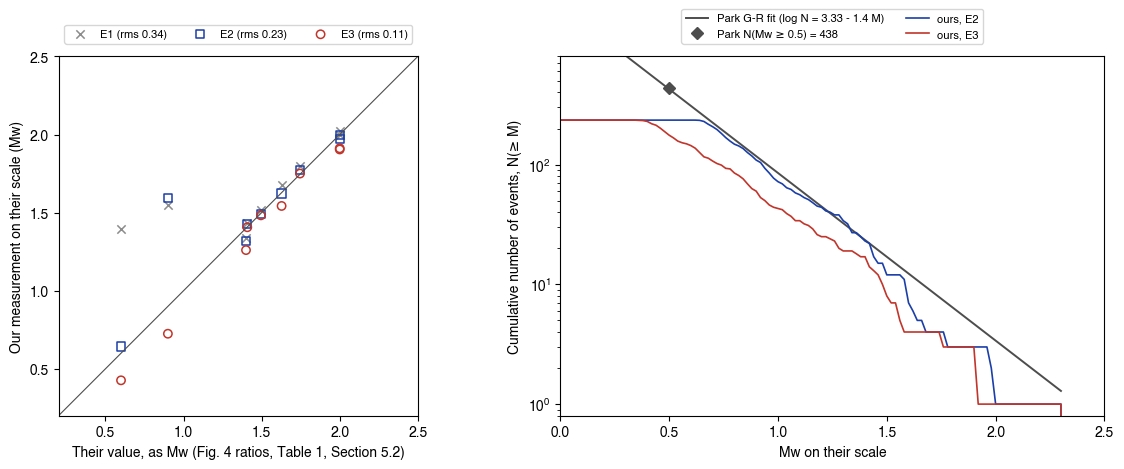

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
for e, mk, col in (('E1', 'x', '0.55'), ('E2', 's', '#1b3fa8'), ('E3', 'o', '#c1352b')):
    kw = dict(color=col) if mk == 'x' else dict(facecolor='none', edgecolor=col)
    ax[0].scatter(val.their_Mw, val[e], marker=mk, s=36, lw=1.1, label=f'{e} (rms {VAL_RMS[e]:.2f})', **kw)
ax[0].plot([0, 2.5], [0, 2.5], color='0.3', lw=0.8); ax[0].set_xlim(0.2, 2.5); ax[0].set_ylim(0.2, 2.5); ax[0].set_aspect('equal')
ax[0].set_xlabel('Their value, as Mw (Fig. 4 ratios, Table 1, Section 5.2)'); ax[0].set_ylabel('Our measurement on their scale (Mw)')
ax[0].legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=3, frameon=True, fontsize=8)
ax[1].semilogy(MS, park_cum, color='0.3', lw=1.4, label=f'Park G-R fit (log N = {PARK["gr_a"]} - {PARK["b"]} M)')
ax[1].plot(PARK['mc'], PARK['n_ge_mc'], 'D', color='0.3', ms=6, label=f'Park N(Mw ≥ {PARK["mc"]}) = {PARK["n_ge_mc"]}')
mm = np.arange(-0.2, 2.5, 0.02)
for e, col in (('E2', '#1b3fa8'), ('E3', '#c1352b')):
    ax[1].semilogy(mm, [(fmf[f'mw_{e}'] >= m).sum() for m in mm], color=col, lw=1.2, label=f'ours, {e}')
ax[1].set_xlim(0, 2.5); ax[1].set_ylim(0.8, 800); ax[1].set_xlabel('Mw on their scale'); ax[1].set_ylabel('Cumulative number of events, N(≥ M)')
ax[1].legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=True, fontsize=8)
plt.tight_layout(); plt.show()

**Their Fig. 6 drawn with our catalog (E3 magnitudes).** In the top panel, events are counted in 10-minute bins.

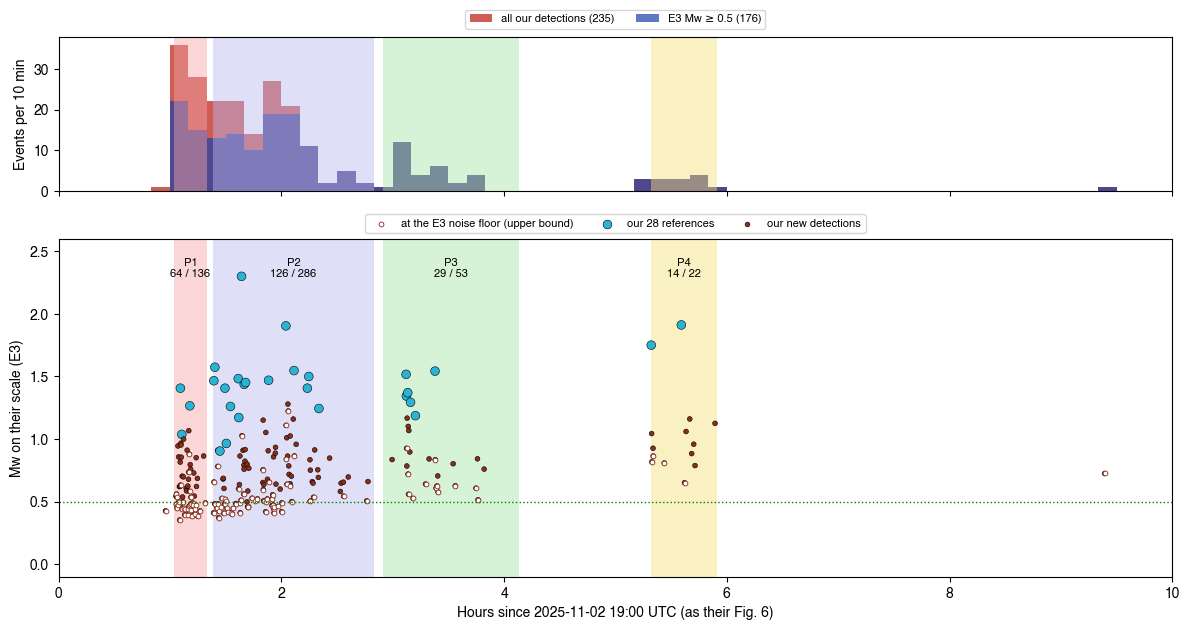

,phase,Park_n,ours_n,Park_Mw,ours_Mw_E3,Park_N_ge_1,ours_N_ge_1_E3,ours_N_ge_1_E2
0,P1,136,64,0.3-1.5,0.4-1.4,14,4,10
1,P2,286,126,0.3-2.3,0.4-2.3,46,24,38
2,P3,53,29,0.5-1.7,0.5-1.5,11,9,11
3,P4,22,14,0.7-2.0,0.7-1.9,6,6,12


Park_N_ge_1 = their N(Mw >= 0.5) x 10^(-b x 0.5) from their per-phase b (Fig. 10); an estimate, not a count.


In [9]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6.4), sharex=True, gridspec_kw=dict(height_ratios=[1, 2.2]))
T0 = pd.Timestamp('2025-11-02 19:00'); h = (fmf.origin - T0).dt.total_seconds() / 3600
bins_ = np.arange(0, 10.01, 1 / 6)
ax[0].hist(h, bins=bins_, color='#c1352b', alpha=0.8, label=f'all our detections ({len(fmf)})')
ax[0].hist(h[fmf.mw_E3 >= PARK['mc']], bins=bins_, color='#1b3fa8', alpha=0.7, label=f'E3 Mw ≥ {PARK["mc"]} ({int((fmf.mw_E3 >= PARK["mc"]).sum())})')
ax[0].set_ylabel('Events per 10 min'); ax[0].legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=True, fontsize=8)
cols = {'P1': '#f4a6a6', 'P2': '#b9b9f0', 'P3': '#a8e6a8', 'P4': '#f6e27a'}
for p in PARK_PHASES.itertuples():
    a, b = (p.t0 - T0).total_seconds() / 3600, (p.t1 - T0).total_seconds() / 3600
    for k in (0, 1): ax[k].axvspan(a, b, color=cols[p.phase], alpha=0.45, lw=0)
    n_ours = int(tab_ph.set_index('phase').ours_n[p.phase]); ax[1].text((a + b) / 2, 2.45, f'{p.phase}\n{n_ours} / {p.n}', ha='center', va='top', fontsize=8)
ax[1].scatter(h, fmf.mw_E3, s=np.where(fmf.is_reference, 40, 12), c=np.where(fmf.is_reference, '#2bb3d6', '#8c2d19'), edgecolors='black', linewidths=0.4)
low = fmf.mw_E3 - floor3 < 0.15; ax[1].scatter(h[low], fmf.mw_E3[low], s=12, facecolor='white', edgecolor='#8c2d19', lw=0.6, label='at the E3 noise floor (upper bound)')
ax[1].axhline(PARK['mc'], color='green', ls=':', lw=1); ax[1].set_ylim(-0.1, 2.6); ax[1].set_xlim(0, 10)
ax[1].set_ylabel('Mw on their scale (E3)'); ax[1].set_xlabel('Hours since 2025-11-02 19:00 UTC (as their Fig. 6)')
ax[1].scatter([], [], s=40, c='#2bb3d6', edgecolors='black', linewidths=0.4, label='our 28 references'); ax[1].scatter([], [], s=12, c='#8c2d19', edgecolors='black', linewidths=0.4, label='our new detections')
ax[1].legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=True, fontsize=8)
plt.tight_layout(); plt.show()
rows = []
for p in PARK_PHASES.itertuples():
    g = fmf[fmf.phase == p.phase]
    rows.append(dict(phase=p.phase, Park_n=p.n, ours_n=len(g), Park_Mw=f'{p.mw_min}-{p.mw_max}', ours_Mw_E3=f'{g.mw_E3.min():.1f}-{g.mw_E3.max():.1f}',
                     Park_N_ge_1=round(p.n_ge_mc * 10 ** (-p.b * (1.0 - PARK['mc']))), ours_N_ge_1_E3=int((g.mw_E3 >= 1.0).sum()), ours_N_ge_1_E2=int((g.mw_E2 >= 1.0).sum())))
display(pd.DataFrame(rows))
print('Park_N_ge_1 = their N(Mw >= 0.5) x 10^(-b x 0.5) from their per-phase b (Fig. 10); an estimate, not a count.')

## 4. Why our catalog is about half the size of theirs

What sections 2 and 3 establish:
- **The same swarm in time.** Both catalogs have the same four phases, empty gaps, first and last events, and the two isolated events at 19:57 and 04:23. Their two-month search and our five-month search both find nothing else.
- **Their scale, replicated.** We reproduce their magnitude scale to within about 0.1 units on the nine events they quote.
- **Where the difference lies.** Measured on that scale, 70–95 % of the 263 extra events are small, below Mw 0.8; the range depends on the estimator (E3 or E2, printed in section 3). Our count also falls short of theirs above Mw 1.0: 43 (E3) to 72 (E2) against their G-R fit of 85. The shortfall is largest in the two busiest phases, P1 and P2, where events come every 10–20 s and often overlap the coda of the one before.

The table below lists the differences in detection method that can produce this. The quantities after it are computed.

In [10]:
cats = {'12×MAD, floor 0.20 (first run)': 'fmf_imsil_catalog_imsil_5_20H_aligned_seg.csv', '12×MAD, no floor': 'fmf_imsil_catalog_imsil_5_20H_aligned_seg_nofloor.csv',
        '10×MAD, floor 0.20': 'fmf_imsil_catalog_imsil_5_20H_aligned_mad10_seg.csv', '10×MAD, no floor (adopted, D23)': 'fmf_imsil_catalog_imsil_5_20H_aligned_mad10_seg_nofloor.csv'}
thr = pd.DataFrame([(k, len(pd.read_csv(f'{DL}/fmf_aligned/catalogs/{v}'))) for k, v in cats.items()], columns=['our threshold variant', 'detections'])
thr['share of Park'] = (thr.detections / PARK['n_total']).round(2); display(thr)
causes = pd.DataFrame([
    ('Stations in the stack', f'{PARK["stations"]} (KMA + KIGAM, ≤ 80 km), 3 components for P and S', f'{len(fst)} KS (≤ 60 km), P on Z, S on 2 components',
     'More channels lower the noise of the stacked CC; a noise-weighted stack lets the many distant channels add without diluting'),
    ('Band', '10–40 Hz', '5–20 Hz', 'A wider band gives more independent samples per window, so the noise CC is lower; small events have more energy above 20 Hz'),
    ('Templates', '1 (ML 1.9)', '28 (25 m references)', 'Ours should recover more of the dissimilar events; it cannot explain a deficit'),
    ('Threshold', 'AIC on the stacked CC; their Fig. 3d shows it just above the noise band (~0.17 on a ~0.12–0.14 baseline)', '10 × MAD per segment (whole-day 10×MAD: 0.12–0.40 by template, notebook 09)', 'Lowering ours from 12 to 10 × MAD added 26 %; theirs is closer to the noise, with visual vetting'),
    ('Vetting', 'every detection checked by eye', 'independent PhaseNet+ picks (notebook 08); no visual cut', 'Visual vetting allows a lower trigger level'),
], columns=['setting', 'Park et al.', 'ours', 'expected effect'])
display(causes)

,our threshold variant,detections,share of Park
0,"12×MAD, floor 0.20 (first run)",187,0.38
1,"12×MAD, no floor",194,0.39
2,"10×MAD, floor 0.20",210,0.42
3,"10×MAD, no floor (adopted, D23)",235,0.47


,setting,Park et al.,ours,expected effect
0,Stations in the stack,"60 (KMA + KIGAM, ≤ 80 km), 3 components for P and S","22 KS (≤ 60 km), P on Z, S on 2 components",More channels lower the noise of the stacked CC; a noise-weighted stack lets the many distant channels add without d...
1,Band,10–40 Hz,5–20 Hz,"A wider band gives more independent samples per window, so the noise CC is lower; small events have more energy abov..."
2,Templates,1 (ML 1.9),28 (25 m references),Ours should recover more of the dissimilar events; it cannot explain a deficit
3,Threshold,AIC on the stacked CC; their Fig. 3d shows it just above the noise band (~0.17 on a ~0.12–0.14 baseline),"10 × MAD per segment (whole-day 10×MAD: 0.12–0.40 by template, notebook 09)","Lowering ours from 12 to 10 × MAD added 26 %; theirs is closer to the noise, with visual vetting"
4,Vetting,every detection checked by eye,independent PhaseNet+ picks (notebook 08); no visual cut,Visual vetting allows a lower trigger level


## 5. Absolute location: epicenter and depth

**The question.** Their cluster sits at 13.6–14.0 km depth (Fig. 7, Fig. S2d). Our relocated cluster sits at about 12.8–13.0 km. Which part of that difference is real?

**Key fact.** Double-difference relocation fixes where events are relative to each other, not where the cluster is. Our two HypoDD runs, the DL relocation (notebook 04) and the joint FMF relocation (notebook 10), place the same 28 reference events about 520 m apart in absolute position. Yet they agree to about 3 m once the centroid is removed. The cluster's absolute position follows the average starting location, so it is set by HYPOINVERSE.

In [11]:
KL = 111.19e3; KO = KL * np.cos(np.radians(35.55))
m = dlr.merge(rel[rel.kind == 'reference'], on='event_id', suffixes=('_dl', '_fmf'))
dN, dE, dZ = (m.latitude_fmf - m.latitude_dl) * KL, (m.longitude_fmf - m.longitude_dl) * KO, (m.depth_km_fmf - m.depth_km_dl) * 1000
rel_shift = np.sqrt((dN - dN.mean()) ** 2 + (dE - dE.mean()) ** 2 + (dZ - dZ.mean()) ** 2)
print(f'28 references, joint FMF run minus DL run: absolute shift N {dN.median():.0f} m, E {dE.median():.0f} m, Z {dZ.median():.0f} m; relative (centroid removed) median {rel_shift.median():.1f} m')
H = {vm: sumio.read_sum(f'{DL}/runs/hypodd_dl/1.HypoInv/{vm}/ImsilDL.sum') for vm in ('kim1983', 'kim2011')}
rows = []
for r in PARK_T1.itertuples():
    t = r.time if r.Index != 2 else pd.Timestamp('2025-11-02 21:02:30')
    for lab, df, cl in (('HYPOINVERSE kim1983', H['kim1983'], ('lat', 'lon', 'depth')), ('HYPOINVERSE kim2011', H['kim2011'], ('lat', 'lon', 'depth')),
                        ('HypoDD, DL run', dlr.assign(time=pd.to_datetime(dlr.origin_time)), ('latitude', 'longitude', 'depth_km')),
                        ('HypoDD, joint FMF run', rel, ('latitude', 'longitude', 'depth_km'))):
        q = df.loc[(pd.to_datetime(df.time) - t).abs().idxmin()]
        rows.append(dict(event=str(r.time)[11:19], solution=lab, dN_m=(q[cl[0]] - r.lat) * KL, dE_m=(q[cl[1]] - r.lon) * KO, dZ_m=(q[cl[2]] - r.depth) * 1000, our_depth_km=q[cl[2]]))
loc = pd.DataFrame(rows); display(loc.groupby('solution')[['dN_m', 'dE_m', 'dZ_m', 'our_depth_km']].median().round(2))
for vm, h_ in H.items():
    big = h_[h_.num >= 40]
    print(f'{vm}: {len(h_)} events, depth median {h_.depth.median():.2f} km; the {len(big)} events with >= 40 phases: depth median {big.depth.median():.2f} km, '
          f'epicenter {big.lat.median():.5f} N {big.lon.median():.5f} E; corr(depth, phases) = {np.corrcoef(h_.depth, h_.num)[0, 1]:+.2f}; ML 1.9 RMS {h_.loc[(h_.time - pd.Timestamp("2025-11-02 20:38:35")).abs().idxmin(), "rms"]:.2f} s')
print(f'Park: depths {PARK["depth_km"][0]}-{PARK["depth_km"][1]} km; Table 1 epicenters {PARK_T1.lat.mean():.5f} N {PARK_T1.lon.mean():.5f} E')

28 references, joint FMF run minus DL run: absolute shift N -516 m, E 143 m, Z -76 m; relative (centroid removed) median 3.0 m


,dN_m,dE_m,dZ_m,our_depth_km
solution,,,,
HYPOINVERSE kim1983,-127.87,-148.36,90.0,13.82
HYPOINVERSE kim2011,-18.90,-76.90,585.0,14.31
"HypoDD, DL run",266.30,-298.99,-803.0,12.98
"HypoDD, joint FMF run",-251.85,-156.50,-880.0,12.90


kim1983: 34 events, depth median 13.21 km; the 7 events with >= 40 phases: depth median 13.79 km, epicenter 35.55020 N 127.29460 E; corr(depth, phases) = +0.36; ML 1.9 RMS 0.15 s
kim2011: 34 events, depth median 14.30 km; the 7 events with >= 40 phases: depth median 14.37 km, epicenter 35.55040 N 127.29510 E; corr(depth, phases) = -0.04; ML 1.9 RMS 0.05 s
Park: depths 13.6-14.0 km; Table 1 epicenters 35.55020 N 127.29624 E


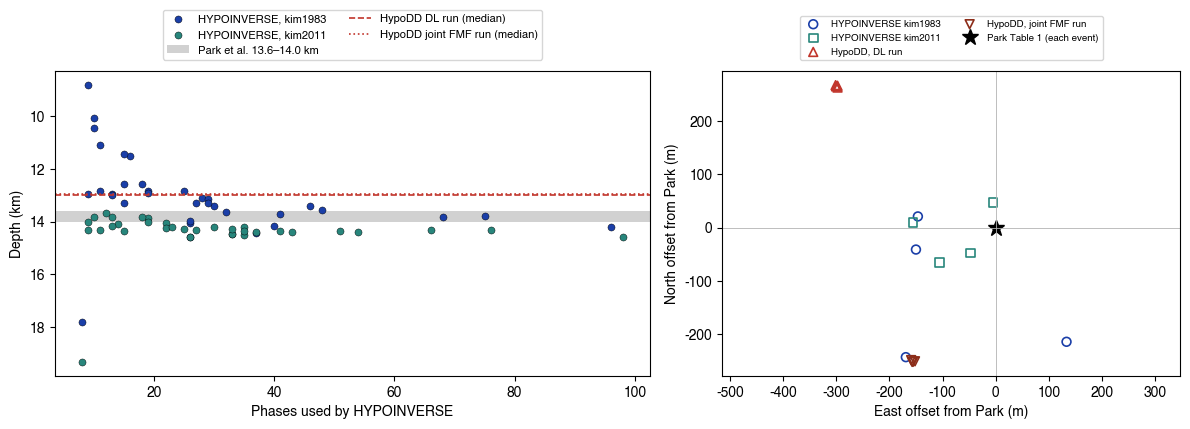

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw=dict(width_ratios=[1.3, 1]))
for vm, col in (('kim1983', '#1b3fa8'), ('kim2011', '#28867c')):
    ax[0].scatter(H[vm].num, H[vm].depth, s=26, color=col, edgecolor='black', lw=0.3, label=f'HYPOINVERSE, {vm}')
ax[0].axhspan(*PARK['depth_km'], color='0.82', lw=0, zorder=0, label='Park et al. 13.6–14.0 km')
for lab, d, ls in (('HypoDD DL run (median)', dlr.depth_km.median(), '--'), ('HypoDD joint FMF run (median)', rel[rel.emax <= 25].depth_km.median(), ':')):
    ax[0].axhline(d, color='#c1352b', ls=ls, lw=1.2, label=lab)
ax[0].invert_yaxis(); ax[0].set_xlabel('Phases used by HYPOINVERSE'); ax[0].set_ylabel('Depth (km)')
ax[0].legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=True, fontsize=8)
for lab, mk, col in (('HYPOINVERSE kim1983', 'o', '#1b3fa8'), ('HYPOINVERSE kim2011', 's', '#28867c'), ('HypoDD, DL run', '^', '#c1352b'), ('HypoDD, joint FMF run', 'v', '#8c2d19')):
    g = loc[loc.solution == lab]; ax[1].scatter(g.dE_m, g.dN_m, marker=mk, s=40, facecolor='none', edgecolor=col, lw=1.2, label=lab)
ax[1].plot(0, 0, '*', color='black', ms=12, label='Park Table 1 (each event)'); ax[1].axhline(0, color='0.7', lw=0.6); ax[1].axvline(0, color='0.7', lw=0.6)
ax[1].set_aspect('equal', adjustable='datalim'); ax[1].set_xlabel('East offset from Park (m)'); ax[1].set_ylabel('North offset from Park (m)')
ax[1].legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=True, fontsize=7)
plt.tight_layout(); plt.show()

## 6. Geometry: plane, extent and thickness

Haenam's SVD plane fit (`joint_science.plane`, verbatim as in notebooks 04, 10 and 11) is used on three of our sets: the 101 events meeting the 25 m rule, and the events whose largest 95 % half-width is ≤ 50 m or ≤ 100 m. The along-strike axis points east, as their profile A–A′ does. In the Park row, `normal_99` is the width of their map box (Fig. 7a), not a 99 % width.

In [13]:
def plane(X):
    center=np.mean(X,axis=0);_,sv,v=np.linalg.svd(X-center,full_matrices=False);n=v[-1]
    if n[2]>0:n=-n
    dip=np.degrees(np.arccos(np.clip(-n[2],-1,1)));strike=(np.degrees(np.arctan2(n[0],n[1]))-90)%360
    s=np.array([np.sin(np.radians(strike)),np.cos(np.radians(strike)),0]);h=np.array([np.cos(np.radians(strike)),-np.sin(np.radians(strike)),0]);down=h*np.cos(np.radians(dip))+np.array([0,0,np.sin(np.radians(dip))])
    return dict(center=center,normal=n,strike=strike,dip=dip,s=s,h=h,down=down,rms=float(np.sqrt(np.mean(((X-center)@n)**2))),sv=sv)
def inplane(ev):
    ev = ev.sort_values('time').reset_index(drop=True).copy(); lat0, lon0 = ev.latitude.mean(), ev.longitude.mean()
    X = np.c_[(ev.longitude - lon0) * 111.19 * np.cos(np.radians(lat0)) * 1000, (ev.latitude - lat0) * 111.19 * 1000, (ev.depth_km - ev.depth_km.mean()) * 1000]
    P = plane(X); R = X - P['center']; u_s = P['s'] if P['s'][0] > 0 else -P['s']           # +x toward the east (their A -> A')
    ev['x'] = R @ u_s; ev['up'] = -(R @ P['down']); ev['nrm'] = R @ P['normal']; return ev, P
SETS = {'25 m rule (101)': r25.assign(emax=r25[['ex95_m', 'ey95_m', 'ez95_m']].max(axis=1)), '≤ 50 m': rel[rel.emax <= 50], '≤ 100 m': rel[rel.emax <= 100]}
rows = []; GEO = {}
q = lambda x, p: np.percentile(x, 50 + p / 2) - np.percentile(x, 50 - p / 2)
for k, ev in SETS.items():
    e, P = inplane(ev); GEO[k] = (e, P)
    rows.append(dict(set=k, n=len(e), strike=P['strike'], dip=P['dip'], dip_toward=(P['strike'] + 90) % 360, rms_thickness_m=P['rms'],
                     along_95=q(e.x, 95), along_99=q(e.x, 99), vertical_95=q(e.up, 95), vertical_99=q(e.up, 99), normal_99=q(e.nrm, 99)))
rows.append(dict(set='Park et al.', n=PARK['n_total'], strike=PARK['strike'], dip=PARK['dip'], dip_toward=(PARK['strike'] + 90) % 360, rms_thickness_m=np.nan,
                 along_95=np.nan, along_99=PARK['extent_lateral_km'] * 1000, vertical_95=np.nan, vertical_99=PARK['extent_vertical_km'] * 1000, normal_99=PARK['box_m'][1]))
geo = pd.DataFrame(rows); display(geo.round(1))
print('A plane striking 268.7 and dipping 88.2 (toward N) is the same as striking 88.7 and dipping 91.8 toward S: both studies find a vertical E-W plane; '
      f'theirs dips {PARK["dip"]} toward S, ours {GEO["25 m rule (101)"][1]["dip"]:.1f} toward N, a {180 - PARK["dip"] - GEO["25 m rule (101)"][1]["dip"]:.1f} degree difference.')
print(f'The dip direction is not resolved: our <= 100 m set gives {GEO["≤ 100 m"][1]["strike"]:.1f} / {GEO["≤ 100 m"][1]["dip"]:.1f} (toward S). Both studies: vertical within ~2 degrees.')

,set,n,strike,dip,dip_toward,rms_thickness_m,along_95,along_99,vertical_95,vertical_99,normal_99
0,25 m rule (101),101,268.7,88.2,358.7,7.4,210.4,237.2,208.6,224.7,37.3
1,≤ 50 m,109,267.9,88.1,357.9,8.4,220.0,275.4,212.3,236.2,46.0
2,≤ 100 m,125,88.6,89.8,178.6,10.2,231.7,271.7,227.8,285.4,65.3
3,Park et al.,498,89.0,89.0,179.0,NaN,NaN,300.0,NaN,350.0,100.0


A plane striking 268.7 and dipping 88.2 (toward N) is the same as striking 88.7 and dipping 91.8 toward S: both studies find a vertical E-W plane; theirs dips 89 toward S, ours 88.2 toward N, a 2.8 degree difference.
The dip direction is not resolved: our <= 100 m set gives 88.6 / 89.8 (toward S). Both studies: vertical within ~2 degrees.


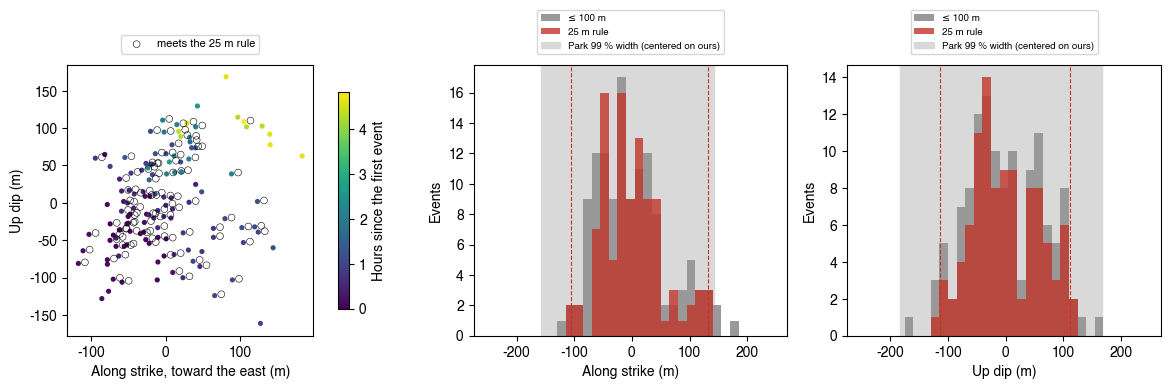

In [14]:
e, P = GEO['≤ 100 m']; e25, _ = GEO['25 m rule (101)']
fig, ax = plt.subplots(1, 3, figsize=(13, 4.0), gridspec_kw=dict(width_ratios=[1.6, 1, 1]))
sc = ax[0].scatter(e.x, e.up, c=(e.time - e.time.min()).dt.total_seconds() / 3600, cmap='viridis', s=14, edgecolor='none')
ax[0].scatter(e25.x, e25.up, s=24, facecolor='none', edgecolor='black', lw=0.4, label='meets the 25 m rule')
ax[0].set_aspect('equal'); ax[0].set_xlabel('Along strike, toward the east (m)'); ax[0].set_ylabel('Up dip (m)'); fig.colorbar(sc, ax=ax[0], shrink=0.8, label='Hours since the first event')
ax[0].legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), frameon=True, fontsize=8)
for k, (col, lab) in enumerate((('x', 'Along strike (m)'), ('up', 'Up dip (m)'))):
    a = ax[k + 1]; a.hist(e[col], bins=np.arange(-250, 251, 15), color='0.6', label='≤ 100 m'); a.hist(e25[col], bins=np.arange(-250, 251, 15), color='#c1352b', alpha=0.8, label='25 m rule')
    w = (PARK['extent_lateral_km'] if col == 'x' else PARK['extent_vertical_km']) * 1000; c = np.median(e25[col])
    a.axvspan(c - w / 2, c + w / 2, color='0.85', zorder=0, label="Park 99 % width (centered on ours)")
    lo, hi = np.percentile(e25[col], [0.5, 99.5]); a.axvline(lo, color='#c1352b', ls='--', lw=0.8); a.axvline(hi, color='#c1352b', ls='--', lw=0.8)
    a.set_xlabel(lab); a.set_ylabel('Events'); a.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=1, frameon=True, fontsize=7)
plt.tight_layout(); plt.show()

## 7. Migration, measured with their recipe

**Their recipe (Section 4 and Fig. 9).**
- The onset point is the centroid of the first 10 events; the onset time is the first event.
- The front is the 90th percentile of distance from the onset in successive groups of 10 events, each group plotted at its mean time. A group's last time is used as a sensitivity test.
- $r = vt$ and $r = \sqrt{4\pi Dt}$ are fitted by least squares in distance.
- The fit is repeated for four zones around the onset (Z1 upper east, Z2 middle east, Z3 lower east, Z4 west). The zone borders are read off their Fig. 9a as directions from the onset: Z1 32–77°, Z2 0–32°, Z3 −45–0°, Z4 the rest, measured from the eastward axis with up positive. They are approximate.

The isolated event at 19:57 lies outside P1 and is left out, as they do (their time zero is the start of P1).

Our own front, by Haenam's protocol of record-breaking events (notebook 11), gave D = 0.50 / 0.59 / 0.63 m²/s for 0.5 / 1 / 2 h windows.

In [15]:
def park_front(e, t0, x0, z0, g=10, tmode='mean'):
    e = e[e.time >= t0].sort_values('time').copy(); e['t'] = (e.time - t0).dt.total_seconds(); e['r'] = np.hypot(e.x - x0, e.up - z0)
    fr = np.array([((e.t.iloc[k:k + g].mean() if tmode == 'mean' else e.t.iloc[k:k + g].max()), np.percentile(e.r.iloc[k:k + g], 90)) for k in range(0, len(e) - g + 1, g)])
    if len(fr) < 2: return dict(n=len(e), groups=len(fr), D=np.nan, rms_D=np.nan, v=np.nan, rms_v=np.nan, front=fr)
    t, r = fr[:, 0], fr[:, 1]; Dg = np.linspace(0.005, 3, 6000); mis = np.array([np.sqrt(np.mean((np.sqrt(4 * np.pi * d * t) - r) ** 2)) for d in Dg])
    v = float((t * r).sum() / (t * t).sum())
    return dict(n=len(e), groups=len(fr), D=float(Dg[mis.argmin()]), rms_D=float(mis.min()), v=v, rms_v=float(np.sqrt(np.mean((v * t - r) ** 2))), front=fr)
def zone_of(e, x0, z0):
    th = np.degrees(np.arctan2(e.up - z0, e.x - x0))
    return np.where((th >= 32) & (th < 77), 'Z1', np.where((th >= 0) & (th < 32), 'Z2', np.where((th >= -45) & (th < 0), 'Z3', 'Z4')))
rows = []; MIG = {}
for k, (e, P) in GEO.items():
    e = e[e.time >= PARK_PHASES.t0[0]].reset_index(drop=True); t0 = e.time.iloc[0]; x0, z0 = e.x.iloc[:10].mean(), e.up.iloc[:10].mean()
    e['zone'] = zone_of(e, x0, z0); MIG[k] = (e, t0, x0, z0)
    for tm in ('mean', 'max'):
        f = park_front(e, t0, x0, z0, tmode=tm); rows.append(dict(set=k, zone='all', group_time=tm, **{c: f[c] for c in ('n', 'groups', 'D', 'rms_D', 'v', 'rms_v')}))
    for z in ('Z1', 'Z2', 'Z3', 'Z4'):
        f = park_front(e[e.zone == z], t0, x0, z0); rows.append(dict(set=k, zone=z, group_time='mean', **{c: f[c] for c in ('n', 'groups', 'D', 'rms_D', 'v', 'rms_v')}))
mig = pd.DataFrame(rows)
mig['Park_D'] = mig.zone.map(PARK['D_zone']); mig['Park_v'] = mig.zone.map(PARK['v_zone'])
display(mig.round(3))
for k, (e, t0, x0, z0) in MIG.items():
    hh = (e.time - t0).dt.total_seconds() / 3600; p1 = e[e.time <= PARK_PHASES.t1[0]]; p4 = e[e.time >= PARK_PHASES.t0[3]]
    print(f'{k}: onset {t0:%H:%M:%S}; corr(time, east) {np.corrcoef(hh, e.x)[0, 1]:+.2f}, corr(time, up) {np.corrcoef(hh, e.up)[0, 1]:+.2f}; '
          f'P1 centroid (east, up) = ({p1.x.mean():.0f}, {p1.up.mean():.0f}) m, P4 = ({p4.x.mean():.0f}, {p4.up.mean():.0f}) m; '
          f'P1 spread (90th pct from onset) {np.percentile(np.hypot(p1.x - x0, p1.up - z0), 90):.0f} m; events west of center {np.mean(e.x < 0):.0%}')

,set,zone,group_time,n,groups,D,rms_D,v,rms_v,Park_D,Park_v
0,25 m rule (101),all,mean,101,10,0.343,30.453,0.024,59.265,NaN,NaN
1,25 m rule (101),all,max,101,10,0.258,37.220,0.016,71.666,NaN,NaN
2,25 m rule (101),Z1,mean,41,4,0.260,21.059,0.019,50.248,0.50,0.034
3,25 m rule (101),Z2,mean,14,1,NaN,NaN,NaN,NaN,0.61,0.044
4,25 m rule (101),Z3,mean,21,2,0.721,9.665,0.055,37.383,0.56,0.048
5,25 m rule (101),Z4,mean,25,2,0.512,11.066,0.081,24.539,0.45,0.050
6,≤ 50 m,all,mean,109,10,0.435,22.897,0.033,46.949,NaN,NaN
7,≤ 50 m,all,max,109,10,0.370,20.001,0.028,43.318,NaN,NaN
8,≤ 50 m,Z1,mean,44,4,0.298,12.340,0.023,40.290,0.50,0.034
9,≤ 50 m,Z2,mean,16,1,NaN,NaN,NaN,NaN,0.61,0.044


25 m rule (101): onset 20:03:28; corr(time, east) +0.49, corr(time, up) +0.68; P1 centroid (east, up) = (-40, -43) m, P4 = (52, 102) m; P1 spread (90th pct from onset) 70 m; events west of center 55%
≤ 50 m: onset 20:03:28; corr(time, east) +0.55, corr(time, up) +0.69; P1 centroid (east, up) = (-43, -47) m, P4 = (80, 96) m; P1 spread (90th pct from onset) 73 m; events west of center 53%
≤ 100 m: onset 20:03:28; corr(time, east) +0.64, corr(time, up) +0.69; P1 centroid (east, up) = (-51, -48) m, P4 = (95, 102) m; P1 spread (90th pct from onset) 84 m; events west of center 55%


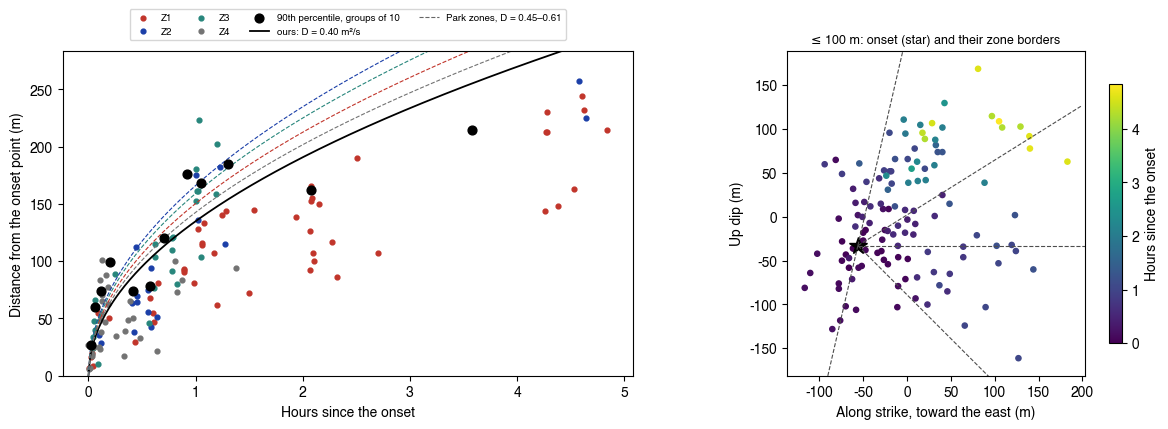

In [16]:
k = '≤ 100 m'; e, t0, x0, z0 = MIG[k]; f = park_front(e, t0, x0, z0)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw=dict(width_ratios=[1.2, 1]))
tt = (e.time - t0).dt.total_seconds() / 3600; rr = np.hypot(e.x - x0, e.up - z0)
zc = {'Z1': '#c1352b', 'Z2': '#1b3fa8', 'Z3': '#28867c', 'Z4': '0.45'}
for z, c in zc.items(): ax[0].scatter(tt[e.zone == z], rr[e.zone == z], s=12, color=c, label=z)
ax[0].scatter(f['front'][:, 0] / 3600, f['front'][:, 1], s=40, color='black', zorder=3, label='90th percentile, groups of 10')
th = np.linspace(0, tt.max(), 300)
ax[0].plot(th, np.sqrt(4 * np.pi * f['D'] * th * 3600), color='black', lw=1.3, label=f'ours: D = {f["D"]:.2f} m²/s')
for z, Dz in PARK['D_zone'].items(): ax[0].plot(th, np.sqrt(4 * np.pi * Dz * th * 3600), color=zc[z], lw=0.8, ls='--')
ax[0].plot([], [], color='0.4', ls='--', lw=0.8, label='Park zones, D = 0.45–0.61')
ax[0].set_xlabel('Hours since the onset'); ax[0].set_ylabel('Distance from the onset point (m)'); ax[0].set_ylim(0, rr.max() * 1.1)
ax[0].legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=4, frameon=True, fontsize=7)
sc = ax[1].scatter(e.x, e.up, c=tt, cmap='viridis', s=14); ax[1].plot(x0, z0, '*', color='black', ms=13)
for ang in (77, 32, 0, -45):
    ax[1].plot([x0, x0 + 300 * np.cos(np.radians(ang))], [z0, z0 + 300 * np.sin(np.radians(ang))], color='0.3', ls='--', lw=0.8)
ax[1].plot([x0, x0 - 300 * np.cos(np.radians(77))], [z0, z0 - 300 * np.sin(np.radians(77))], color='0.3', ls='--', lw=0.8)
ax[1].set_xlim(e.x.min() - 20, e.x.max() + 20); ax[1].set_ylim(e.up.min() - 20, e.up.max() + 20); ax[1].set_aspect('equal')
ax[1].set_xlabel('Along strike, toward the east (m)'); ax[1].set_ylabel('Up dip (m)'); fig.colorbar(sc, ax=ax[1], shrink=0.8, label='Hours since the onset')
ax[1].set_title(f'{k}: onset (star) and their zone borders', fontsize=9)
plt.tight_layout(); plt.show()

## 8. Focal mechanisms tested against our station amplitudes

Their mechanisms (Table 1) show left-lateral strike slip on a plane striking 89–92° and dipping 68–73°, with a normal component (rake −22 to −41°). Two tests with our data:
1. **Plane.** Their nodal plane 1 against the planes fitted to their hypocenters and to ours.
2. **Radiation.** Their ML 1.9 mechanism predicts how strong P is relative to S at each station. Our ML 1.9 records give the observed P/S amplitude ratio at each station: 5–20 Hz velocity, P peak on Z in the first 0.6 s, S peak on the horizontal vector in the first 1.0 s. Take-off angles come from TauP in kim1983 for a 13.8 km source. If the mechanism is right, observed and predicted ratios rank the stations alike. One station matters in particular. IMSB is our closest station at 6.9 km, yet its template P signal-to-noise ratio is low (notebook 07: IMSB.Z is often dropped).

In [17]:
def radiation(strike, dip, rake, az, toa):
    # far-field P, SV, SH radiation coefficients (Aki & Richards 1980, eq. 4.89); angles in degrees, toa from the downward vertical
    f, d, l, ph, i = map(np.radians, (strike, dip, rake, az, toa)); a = ph - f
    FP = np.cos(l) * np.sin(d) * np.sin(i) ** 2 * np.sin(2 * a) - np.cos(l) * np.cos(d) * np.sin(2 * i) * np.cos(a) + np.sin(l) * np.sin(2 * d) * (np.cos(i) ** 2 - np.sin(i) ** 2 * np.sin(a) ** 2) + np.sin(l) * np.cos(2 * d) * np.sin(2 * i) * np.sin(a)
    FSV = np.sin(l) * np.cos(2 * d) * np.cos(2 * i) * np.sin(a) - np.cos(l) * np.cos(d) * np.cos(2 * i) * np.cos(a) + 0.5 * np.cos(l) * np.sin(d) * np.sin(2 * i) * np.sin(2 * a) - 0.5 * np.sin(l) * np.sin(2 * d) * np.sin(2 * i) * (1 + np.sin(a) ** 2)
    FSH = np.cos(l) * np.cos(d) * np.cos(i) * np.sin(a) + np.cos(l) * np.sin(d) * np.sin(i) * np.cos(2 * a) + np.sin(l) * np.cos(2 * d) * np.cos(i) * np.cos(a) - 0.5 * np.sin(l) * np.sin(2 * d) * np.sin(i) * np.sin(2 * a)
    return FP, FSV, FSH
taup = TauPyModel(model='/home/msseo/works/72.2025_Imsil_swarm/data/stations/taup/kim1983_buan.npz')
SRC = (PARK_T1.lat[1], PARK_T1.lon[1], PARK_T1.depth[1]); MECH = PARK_T1.plane1[1]
rows = []
for f in sorted(glob.glob(f'{REF_DIR}/*Z.sac')):
    sta = obspy.read(f, headonly=True)[0].stats.station; v = picks[sta]
    if 'P' not in v or 'S' not in v or v['dist'] > 60: continue
    st = obspy.Stream([obspy.read(g)[0] for g in sorted(glob.glob(f.replace('Z.sac', '?.sac')))])
    for tr in st:
        tr.data = tr.data.astype(np.float64); tr.detrend('linear'); tr.taper(0.05); tr.filter('bandpass', freqmin=5, freqmax=20, corners=4, zerophase=True)
        if v['prefix'] == 'HG': tr.integrate(); tr.filter('bandpass', freqmin=5, freqmax=20, corners=4, zerophase=True)
    z = st.select(component='Z')[0]; hz = [tr for tr in st if tr.stats.channel[-1] in 'NE12']
    if len(hz) < 2: continue
    nh = min(len(hz[0].data), len(hz[1].data)); trh = hz[0].copy(); trh.data = np.sqrt(hz[0].data[:nh] ** 2 + hz[1].data[:nh] ** 2)
    pz = peak(z, v['P'] - 0.05, v['P'] + 0.6); ps = peak(trh, v['S'] - 0.05, v['S'] + 1.0)
    dkm, az, _ = gps2dist_azimuth(SRC[0], SRC[1], v['lat'], v['lon'])
    arrP = taup.get_travel_times(SRC[2], dkm / 1000 / 111.19, ['p', 'P', 'Pn']); arrS = taup.get_travel_times(SRC[2], dkm / 1000 / 111.19, ['s', 'S', 'Sn'])
    FP, FSV, FSH = radiation(*MECH, az, arrP[0].takeoff_angle); _, SV2, SH2 = radiation(*MECH, az, arrS[0].takeoff_angle)
    rows.append(dict(station=sta, dist_km=v['dist'], az=az, toa_P=arrP[0].takeoff_angle, pred_P=abs(FP), pred_S=np.hypot(SV2, SH2), obs_P_over_S=pz / ps))
rad = pd.DataFrame(rows); rad['pred_P_over_S'] = rad.pred_P / rad.pred_S
rho, pval = sps.spearmanr(np.log10(rad.pred_P_over_S), np.log10(rad.obs_P_over_S))
rad['rank_obs'] = rad.obs_P_over_S.rank().astype(int); rad['rank_pred'] = rad.pred_P_over_S.rank().astype(int)
display(rad.sort_values('dist_km').head(12).round(3))
imsb = rad.set_index('station').loc['IMSB']
print(f'{len(rad)} stations within 60 km; Spearman correlation of predicted vs observed log(P/S) = {rho:+.2f} (p = {pval:.3f})')
print(f'IMSB: predicted |F_P| = {imsb.pred_P:.2f} (median of all {rad.pred_P.median():.2f}); predicted P/S rank {imsb.rank_pred} of {len(rad)}, observed rank {imsb.rank_obs}')

,station,dist_km,az,toa_P,pred_P,pred_S,obs_P_over_S,pred_P_over_S,rank_obs,rank_pred
6,IMSB,6.980,351.976,153.216,0.187,0.560,0.065,0.333,4,3
14,NAWB,16.947,147.533,129.201,0.245,0.780,0.197,0.314,11,2
18,SIDA,19.603,314.351,125.152,0.647,0.698,0.420,0.926,17,15
13,MALA,22.059,12.200,122.030,0.314,0.609,0.035,0.515,3,10
8,JASA,23.519,59.667,120.399,0.177,0.383,0.462,0.462,18,9
19,SUCA,24.260,216.194,119.620,0.933,0.360,0.120,2.592,9,20
9,JEU2,33.846,259.364,112.104,0.540,0.816,0.084,0.662,5,13
20,TAIA,34.852,288.767,111.521,0.323,0.943,0.123,0.342,10,4
4,GKSA,36.064,190.349,110.854,0.328,0.944,0.035,0.348,2,5
1,CHOA,36.079,333.348,110.842,0.924,0.266,0.295,3.474,14,22


22 stations within 60 km; Spearman correlation of predicted vs observed log(P/S) = +0.59 (p = 0.004)
IMSB: predicted |F_P| = 0.19 (median of all 0.40); predicted P/S rank 3.0 of 22, observed rank 4.0


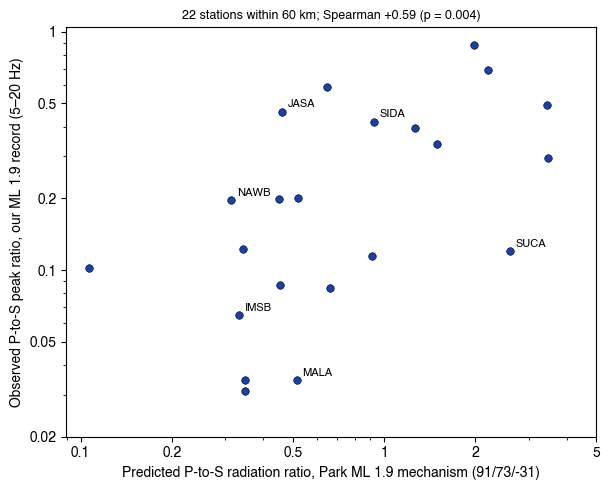

,source,strike,dip,rake
0,"Park, nodal plane 1 (Table 1, 4 events)",89-92,68-73 toward S,-41 to -22
1,"Park, hypocenter plane (Fig. 7)",89,89 toward S,
2,"Ours, hypocenter plane (25 m rule)",88.7,88.2 toward N,


In [18]:
fig, ax = plt.subplots(figsize=(6.2, 5))
ax.scatter(rad.pred_P_over_S, rad.obs_P_over_S, s=30, color='#1b3fa8', edgecolor='black', lw=0.4)
for r in rad.itertuples():
    if r.dist_km < 25 or r.station == 'IMSB': ax.annotate(r.station, (r.pred_P_over_S, r.obs_P_over_S), xytext=(4, 3), textcoords='offset points', fontsize=8)
import matplotlib.ticker as mticker
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('Predicted P-to-S radiation ratio, Park ML 1.9 mechanism (91/73/-31)'); ax.set_ylabel('Observed P-to-S peak ratio, our ML 1.9 record (5–20 Hz)')
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:g}')); axis.set_minor_formatter(mticker.NullFormatter())
ax.set_xticks([0.1, 0.2, 0.5, 1, 2, 5]); ax.set_yticks([0.02, 0.05, 0.1, 0.2, 0.5, 1])
ax.set_title(f'{len(rad)} stations within 60 km; Spearman {rho:+.2f} (p = {pval:.3f})', fontsize=9)
plt.tight_layout(); plt.show()
fm = pd.DataFrame([dict(source='Park, nodal plane 1 (Table 1, 4 events)', strike=f'{min(p[0] for p in PARK_T1.plane1)}-{max(p[0] for p in PARK_T1.plane1)}', dip=f'{min(p[1] for p in PARK_T1.plane1)}-{max(p[1] for p in PARK_T1.plane1)} toward S', rake=f'{min(p[2] for p in PARK_T1.plane1)} to {max(p[2] for p in PARK_T1.plane1)}'),
                   dict(source='Park, hypocenter plane (Fig. 7)', strike=str(PARK['strike']), dip=f'{PARK["dip"]} toward S', rake=''),
                   dict(source='Ours, hypocenter plane (25 m rule)', strike=f'{(GEO["25 m rule (101)"][1]["strike"] - 180):.1f}', dip=f'{GEO["25 m rule (101)"][1]["dip"]:.1f} toward N', rake='')])
display(fm)

## 9. Waveform similarity against time (their Fig. 11): a time effect or a distance effect?

**What they found.** Peak three-component-averaged CC between events of Mw ≥ 0.9 drops with origin-time separation. At MALA it goes from about 0.63 to 0.48, at NAWB from about 0.39 to 0.25 (means read off Fig. 11c, d). They read this as gradual change of the waveforms in time (Section 5.6).

**The same measurement on our events.** Events of E3 Mw ≥ 0.9 at MALA and NAWB, 10–40 Hz velocity, 4 s windows from 0.5 s before to 3.5 s after S (their dt.cc window), lags within ±0.7 s. CC functions are averaged over E, N, Z before the peak is taken.

**The test.** Because the swarm migrates, events far apart in time are also far apart in space. At 10–40 Hz the S wavelength is about 90–360 m, comparable to the size of the cluster. For pairs whose relocations have 95 % half-widths ≤ 50 m, CC is regressed on time separation and on distance together. This shows which of the two carries the trend.

In [19]:
sel = fmf.index[fmf.mw_E3 >= 0.9].to_numpy(); BANDCC = PARK['dtcc']['band']; MAXLAG = 70; W0, W1 = PARK['dtcc']['win']
def cc_matrix(sta):
    v = picks[sta]; wins = {}
    for comp in sorted(v['comps']):
        tr = load_band(v['net'], sta, v['prefix'], comp, BANDCC, 1 if v['prefix'] == 'HG' else 0)
        t0_, fs = tr.stats.starttime, tr.stats.sampling_rate; n = int(round((W1 - W0) * fs))
        a = []; b = []
        for i in sel:
            ts = v['S'] + (t_ev[i] - o_ref) + W0; k = int(round((ts - t0_) * fs))
            a.append(tr.data[k:k + n].copy()); b.append(tr.data[k - MAXLAG:k + n + MAXLAG].copy())
        wins[comp] = (np.array(a), np.array(b))
    M = np.full((len(sel), len(sel)), np.nan)
    for i in range(len(sel)):
        for j in range(i + 1, len(sel)):
            acc = 0
            for comp, (a, b) in wins.items():
                x = a[i] - a[i].mean(); y = b[j]
                c = np.correlate(y, x, mode='valid'); en = np.convolve(y ** 2, np.ones(len(x)), mode='valid')
                acc = acc + c / np.sqrt((x ** 2).sum() * en + 1e-30)
            M[i, j] = M[j, i] = np.max(acc / len(wins))
    return M
CCM = {sta: cc_matrix(sta) for sta in ('MALA', 'NAWB')}
ts_sel = fmf.origin[sel].to_numpy(); iu = np.triu_indices(len(sel), 1)
DT = np.abs((ts_sel[:, None] - ts_sel[None, :]) / np.timedelta64(1, 's'))[iu]
print(f'{len(sel)} events of E3 Mw >= 0.9 (theirs: Mw >= 0.9 events, ~90 in their Fig. 11 matrices); {len(DT)} pairs')
binsec = np.arange(0, 16001, 1000); TREND = {}
for sta, M in CCM.items():
    cc = M[iu]; mb = [np.nanmean(cc[(DT >= a) & (DT < a + 1000)]) for a in binsec[:-1]]
    TREND[sta] = (np.array(mb), cc)
    print(f'{sta}: mean CC in the first 1000 s {mb[0]:.2f}, at 8000-9000 s {mb[8]:.2f}, at 14000-15000 s {mb[14]:.2f}; Spearman(CC, dt) {sps.spearmanr(cc, DT, nan_policy="omit")[0]:+.2f}')

60 events of E3 Mw >= 0.9 (theirs: Mw >= 0.9 events, ~90 in their Fig. 11 matrices); 1770 pairs
MALA: mean CC in the first 1000 s 0.70, at 8000-9000 s 0.74, at 14000-15000 s 0.61; Spearman(CC, dt) -0.18
NAWB: mean CC in the first 1000 s 0.44, at 8000-9000 s 0.44, at 14000-15000 s 0.34; Spearman(CC, dt) -0.22


,station,pairs,corr_cc_dt,corr_cc_dist,corr_dt_dist,beta_dist_per_sd,t_dist,beta_dt_per_sd,t_dt
0,MALA,1326,-0.266,-0.434,0.508,-0.056,-14.070,-0.008,-2.104
1,NAWB,1326,-0.229,-0.557,0.508,-0.092,-22.474,0.011,2.766


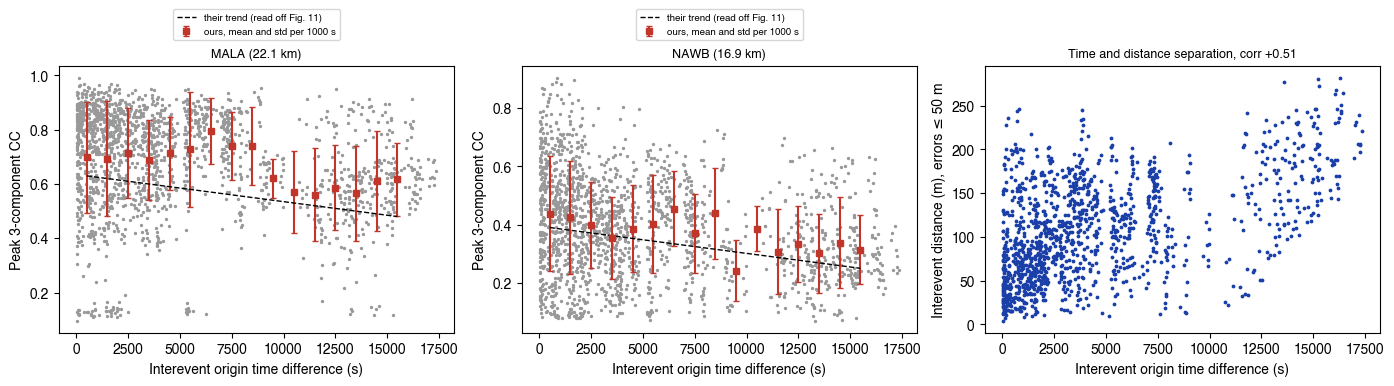

In [20]:
def xyz(i):
    t = fmf.origin[i]; d = (rel.time - t).abs(); j = d.idxmin()
    if d[j].total_seconds() > 1.5 or rel.emax[j] > 50: return None
    r = rel.loc[j]; return np.array([(r.longitude - 127.2945) * KO, (r.latitude - 35.548) * KL, r.depth_km * 1000])
XYZ = [xyz(i) for i in sel]; good = np.array([x is not None for x in XYZ])
rows = []
for sta, (mb, cc) in TREND.items():
    ii, jj = iu; m_ = good[ii] & good[jj] & np.isfinite(cc)
    dist = np.array([np.linalg.norm(XYZ[a] - XYZ[b]) for a, b in zip(ii[m_], jj[m_])]); dt_ = DT[m_]; y = cc[m_]
    Xd = np.c_[np.ones_like(dist), (dist - dist.mean()) / dist.std(), (dt_ - dt_.mean()) / dt_.std()]
    beta, *_ = np.linalg.lstsq(Xd, y, rcond=None); res = y - Xd @ beta; cov = np.linalg.inv(Xd.T @ Xd) * res.var(ddof=3); se = np.sqrt(np.diag(cov))
    rows.append(dict(station=sta, pairs=int(m_.sum()), corr_cc_dt=np.corrcoef(y, dt_)[0, 1], corr_cc_dist=np.corrcoef(y, dist)[0, 1], corr_dt_dist=np.corrcoef(dt_, dist)[0, 1],
                     beta_dist_per_sd=beta[1], t_dist=beta[1] / se[1], beta_dt_per_sd=beta[2], t_dt=beta[2] / se[2]))
sim = pd.DataFrame(rows); display(sim.round(3))
fig, ax = plt.subplots(1, 3, figsize=(14, 4.0))
for k, (sta, (mb, cc)) in enumerate(TREND.items()):
    ax[k].scatter(DT, cc, s=2, color='0.6'); ax[k].errorbar(binsec[:-1] + 500, mb, yerr=[np.nanstd(cc[(DT >= a) & (DT < a + 1000)]) for a in binsec[:-1]], fmt='s', color='#c1352b', ms=5, capsize=2, label='ours, mean and std per 1000 s')
    their = {'MALA': (0.63, 0.48), 'NAWB': (0.39, 0.25)}[sta]; ax[k].plot([500, 15500], their, color='black', ls='--', lw=1, label='their trend (read off Fig. 11)')
    ax[k].set_xlabel('Interevent origin time difference (s)'); ax[k].set_ylabel('Peak 3-component CC'); ax[k].set_title(f'{sta} ({picks[sta]["dist"]:.1f} km)', fontsize=9)
    ax[k].legend(loc='lower center', bbox_to_anchor=(0.5, 1.08), ncol=1, frameon=True, fontsize=7)
ii, jj = iu; m_ = good[ii] & good[jj]; dist = np.array([np.linalg.norm(XYZ[a] - XYZ[b]) for a, b in zip(ii[m_], jj[m_])])
ax[2].scatter(DT[m_], dist, s=3, color='#1b3fa8'); ax[2].set_xlabel('Interevent origin time difference (s)'); ax[2].set_ylabel('Interevent distance (m), errors ≤ 50 m')
ax[2].set_title(f'Time and distance separation, corr {np.corrcoef(DT[m_], dist)[0, 1]:+.2f}', fontsize=9)
plt.tight_layout(); plt.show()

## 10. The b value and the magnitude scale

**Their result.** b = 1.40 ± 0.07 overall, falling from 1.79 in P1 to 1.17 in P4 (Figs 5, 10). They call it high compared with 0.9–1.1 for background Korean seismicity and 0.76–1.04 for other Korean sequences.

**The scale matters.** Their magnitudes are $M = C_1 + C_2\log_{10} r$ with $C_2 = 0.73$, taken from other studies (Hong et al., 2024; Lee et al., 2024) rather than fitted at Imsil. The Mw conversion is close to a pure shift (section 3). Any b value measured on such a scale equals the slope of the amplitude-ratio distribution divided by $C_2$, so b scales as $1/C_2$:
$$b(C_2') = b(0.73)\times 0.73/C_2'.$$
Two physical limits bracket $C_2$:
- $2/3$ for moment magnitude when the 5–20 Hz band lies below both events' corner frequencies, so that amplitude is proportional to seismic moment;
- $1$ for a local magnitude defined as log amplitude.

Their 0.73 lies near the moment limit. Background b values quoted from regional ML catalogs would correspond to the other limit. The relative fall from P1 to P4 is the same on every scale; only the level changes.

**Can Imsil itself fix $C_2$?** Not well. Regressing a catalog magnitude on the measured ratio gives a slope that is biased low when the magnitudes carry errors and span a narrow range: 24 KMA events cover only ML 1.0–1.9. The second table shows this.

In [21]:
lrE3 = lr3
sc_ = pd.DataFrame([('moment, below the corner frequency (A ∝ M0)', 2 / 3), ('Park et al. (fixed from Hong et al., 2024)', PARK['c2']), ('local magnitude = log amplitude', 1.0)], columns=['scale', 'C2'])
for p in ['all'] + list(PARK_PHASES.phase):
    b0 = PARK['b'] if p == 'all' else float(PARK_PHASES.set_index('phase').b[p]); sc_[f'b {p}'] = b0 * PARK['c2'] / sc_.C2
display(sc_.round(2))
def slope_vs_ratio(path, col):
    m = pd.read_csv(path); m['t'] = pd.to_datetime(m.origin_time); x, y = [], []
    for r in m.dropna(subset=[col]).itertuples():
        i = nearest(r.t)
        if abs((fmf.origin[i] - r.t).total_seconds()) < 2: x.append(lrE3[i]); y.append(getattr(r, col))
    return (np.polyfit(x, y, 1)[0], len(x), np.ptp(y)) if len(x) >= 4 else (np.nan, len(x), np.nan)
emp = [('KMA ML', np.polyfit([lrE3[nearest(t)] for t in kma.origin_time_UTC], kma.ML, 1)[0], len(kma), np.ptp(kma.ML))]
for lab, p in (('our ML, run A (D4)', 'full_period'), ('our ML, run B (D4)', 'full_period_resp_current')):
    for col in ('ml_min3', 'ml_min1'): emp.append((f'{lab}, {col}', *slope_vs_ratio(f'{DL}/local_magnitudes/{p}/full_period_ML.csv', col)))
emp = pd.DataFrame(emp, columns=['magnitude regressed on log10 ratio (E3)', 'slope', 'events', 'magnitude range']); display(emp.round(2))
print(f'their scale (C2 = {PARK["c2"]}): b = {PARK["b"]} overall, P1 {PARK_PHASES.b[0]} -> P4 {PARK_PHASES.b[3]}; at C2 = 1 the same data give {PARK["b"] * PARK["c2"]:.2f}, P1 {PARK_PHASES.b[0] * PARK["c2"]:.2f} -> P4 {PARK_PHASES.b[3] * PARK["c2"]:.2f}')
mE3 = fmf.mw_E3[fmf.mw_E3 - floor3 >= 0.15]; BOURS = {}
for mc in (0.8, 0.9, 1.0):
    x_ = mE3[mE3 >= mc]; b_ = np.log10(np.e) / (x_.mean() - mc); BOURS[mc] = (b_, b_ / np.sqrt(len(x_)), len(x_))
    print(f'our catalog on their scale (E3, events above the noise floor), Mc {mc}: b = {b_:.2f} +/- {b_ / np.sqrt(len(x_)):.2f} (Aki 1965, N = {len(x_)})')

,scale,C2,b all,b P1,b P2,b P3,b P4
0,"moment, below the corner frequency (A ∝ M0)",0.67,1.53,1.96,1.60,1.39,1.28
1,"Park et al. (fixed from Hong et al., 2024)",0.73,1.40,1.79,1.46,1.27,1.17
2,local magnitude = log amplitude,1.00,1.02,1.31,1.07,0.93,0.85


,magnitude regressed on log10 ratio (E3),slope,events,magnitude range
0,KMA ML,0.27,24,0.90
1,"our ML, run A (D4), ml_min3",0.63,8,0.80
2,"our ML, run A (D4), ml_min1",0.35,14,0.85
3,"our ML, run B (D4), ml_min3",0.63,14,1.03
4,"our ML, run B (D4), ml_min1",0.34,19,1.03


their scale (C2 = 0.73): b = 1.4 overall, P1 1.79 -> P4 1.17; at C2 = 1 the same data give 1.02, P1 1.31 -> P4 0.85
our catalog on their scale (E3, events above the noise floor), Mc 0.8: b = 1.30 +/- 0.15 (Aki 1965, N = 74)
our catalog on their scale (E3, events above the noise floor), Mc 0.9: b = 1.33 +/- 0.18 (Aki 1965, N = 56)
our catalog on their scale (E3, events above the noise floor), Mc 1.0: b = 1.27 +/- 0.20 (Aki 1965, N = 40)


## 11. Comprehensive summary

In [22]:
F = mig[(mig.set == '≤ 100 m') & (mig.zone == 'all') & (mig.group_time == 'mean')].iloc[0]; F25 = mig[(mig.set == '25 m rule (101)') & (mig.zone == 'all') & (mig.group_time == 'mean')].iloc[0]
e100, t0_, x0_, z0_ = MIG['≤ 100 m']; hh_ = (e100.time - t0_).dt.total_seconds() / 3600
g25 = geo.set_index('set').loc['25 m rule (101)']; hl = loc.groupby('solution')[['dN_m', 'dE_m', 'dZ_m']].median()
e25_, _, x25, z25 = MIG['25 m rule (101)']; p1_ = e25_[e25_.time <= PARK_PHASES.t1[0]]; P1R = np.percentile(np.hypot(p1_.x - x25, p1_.up - z25), 90)
big83 = H['kim1983'][H['kim1983'].num >= 40].depth.median(); big11 = H['kim2011'][H['kim2011'].num >= 40].depth.median()
summary = pd.DataFrame([
    ('Timing: phases, gaps, isolated events', 'P1-P4; gaps empty; Mw 0.6 at ~19:57 and Mw 0.9 at ~04:23; nothing else in 2 months',
     f'same four phases, gaps empty, isolated events at 19:57:38 and 04:23:32; nothing else in 5 months', 'agree'),
    ('Catalog size', f'{PARK["n_total"]} (P1-P4: {", ".join(str(n) for n in PARK_PHASES.n)})', f'{len(fmf)} = {len(fmf) / PARK["n_total"]:.0%} (P1-P4: {", ".join(str(n) for n in tab_ph.ours_n)})',
     'differ: theirs has more stations (60 vs 22), a wider band, a threshold near the noise plus visual vetting'),
    ('Magnitude scale', 'r to ML 1.9 at 5-20 Hz, M = 2.07 + 0.73 log r, Mw = M + ~0.23', f'replicated: rms {VAL_RMS["E3"]:.2f} (E3) on the 9 events they quote', 'agree'),
    ('Where the extra events are', 'Mc = Mw 0.5; N(>= 0.5) = 438; G-R fit N(>= 1.0) = 85', f'N(>= 1.0) = {int((fmf.mw_E3 >= 1).sum())} (E3) - {int((fmf.mw_E2 >= 1).sum())} (E2); N(>= 0.5) = {int((fmf.mw_E3 >= .5).sum())}-{int((fmf.mw_E2 >= .5).sum())}',
     f'{min(BELOW08.values()):.0%}-{max(BELOW08.values()):.0%} of the difference is below Mw 0.8; the rest mostly in P1-P2'),
    ('Absolute depth', f'{PARK["depth_km"][0]}-{PARK["depth_km"][1]} km (joint inversion, Kim 2011 start)', f'HYPOINVERSE >= 40 phases: {big83:.2f} km (kim1983), {big11:.2f} km (kim2011); HypoDD clusters 12.8-13.0 km',
     'agree for the well-recorded events; our HypoDD depth carries the average start depth of poorly recorded events'),
    ('Epicenter', f'{PARK_T1.lat.mean():.5f} N {PARK_T1.lon.mean():.5f} E', f'HYPOINVERSE kim1983 median offset N {hl.loc["HYPOINVERSE kim1983", "dN_m"]:.0f} m, E {hl.loc["HYPOINVERSE kim1983", "dE_m"]:.0f} m; kim2011 N {hl.loc["HYPOINVERSE kim2011", "dN_m"]:.0f} m, E {hl.loc["HYPOINVERSE kim2011", "dE_m"]:.0f} m',
     'agree within ~150 m (absolute location precision)'),
    ('Plane', f'{PARK["strike"]} / {PARK["dip"]} (toward S)', f'{g25.strike:.1f} / {g25.dip:.1f} (= {g25.strike - 180:.1f}, dipping {g25.dip:.1f} toward N)', 'agree: vertical E-W plane; dips differ by ~3 degrees'),
    ('Extent (99 %)', f'{PARK["extent_lateral_km"] * 1000:.0f} m along strike x {PARK["extent_vertical_km"] * 1000:.0f} m vertical; map box {PARK["box_m"][0]} x {PARK["box_m"][1]} m',
     f'{g25.along_99:.0f} x {g25.vertical_99:.0f} m; thickness (99 %) {g25.normal_99:.0f} m, RMS {g25.rms_thickness_m:.1f} m', 'ours smaller and much thinner: fewer small events at the margins; CC >= 0.7 at 5-20 Hz vs CC >= 0.2'),
    ('Migration direction', 'starts lower west, spreads east and up-dip; P1 within ~70 m of the onset', f'corr(time, east) {np.corrcoef(hh_, e100.x)[0, 1]:+.2f}, corr(time, up) {np.corrcoef(hh_, e100.up)[0, 1]:+.2f}; P1 lower west, P4 upper east; P1 90th pct {P1R:.0f} m (25 m set)', 'agree'),
    ('Diffusivity, their recipe', 'zones 0.45-0.61 m2/s', f'all zones {F25.D:.2f} (25 m) - {F.D:.2f} (<= 100 m) m2/s; Haenam front 0.50-0.63 (notebook 11)', 'agree within the method scatter; zone fits on our catalog have only 1-4 groups'),
    ('Mechanism vs station amplitudes', 'left-lateral strike slip, 91/73/-31 for the ML 1.9', f'predicted vs observed P/S at {len(rad)} stations: Spearman {rho:+.2f} (p = {pval:.3f}); IMSB predicted rank {int(imsb.rank_pred)}/{len(rad)}, observed {int(imsb.rank_obs)}',
     ('our amplitudes support their mechanism' if pval < 0.05 else 'not supported by our amplitudes') + f'; IMSB lies near a P nodal direction (|F_P| {imsb.pred_P:.2f} vs median {rad.pred_P.median():.2f}), which explains its weak P'),
    ('Waveform similarity vs time', 'MALA 0.63 -> 0.48, NAWB 0.39 -> 0.25; read as temporal change', 'same decrease; ' + '; '.join(f'{r.station}: t(time) {r.t_dt:+.1f}, t(distance) {r.t_dist:+.1f}' for r in sim.itertuples()),
     'the decrease follows inter-event distance (the swarm migrates), not time' if all(abs(r.t_dist) > 3 * abs(r.t_dt) for r in sim.itertuples()) else 'time and distance both contribute'),
    ('b value', '1.40 +/- 0.07 overall, 1.79 -> 1.17 (P1 -> P4); "high"', f'ours on their scale: {BOURS[0.9][0]:.2f} +/- {BOURS[0.9][1]:.2f} (Mc 0.9, N = {BOURS[0.9][2]}); b scales as 1/C2: {PARK["b"] * PARK["c2"] / (2 / 3):.2f} (C2 = 2/3) to {PARK["b"] * PARK["c2"]:.2f} (C2 = 1)',
     'level agrees on their scale; whether it is "high" depends on C2, which is borrowed, not fitted at Imsil'),
], columns=['topic', 'Park et al. (2026)', 'this study', 'verdict / cause'])
display(summary)
s9 = sim.set_index('station')
take = [
    f'1. Same swarm in time: four phases, empty gaps, the 19:57 and 04:23 isolated events; our catalog holds {len(fmf) / PARK["n_total"]:.0%} of theirs ({", ".join(f"{r.phase} {r.ours_share:.0%}" for r in tab_ph.itertuples())}).',
    f'2. Their magnitude scale is reproduced to {VAL_RMS["E3"]:.2f} rms; {min(BELOW08.values()):.0%}-{max(BELOW08.values()):.0%} of the {DEFICIT} extra events are below Mw 0.8, the rest mainly in the busy phases P1-P2. Main causes: 60 vs 22 stations, 10-40 vs 5-20 Hz, a near-noise threshold with visual vetting vs 10 x MAD.',
    f'3. Depth: their 13.6-14.0 km matches our well-recorded HYPOINVERSE events ({big83:.2f} km kim1983); our HypoDD clusters at ~12.9 km carry the mean start depth of poorly recorded events (two runs differ by ~520 m absolute, 3 m relative).',
    f'4. Geometry agrees (vertical E-W plane); ours is {g25.along_99:.0f} x {g25.vertical_99:.0f} m and {g25.normal_99:.0f} m thick (99 %) vs their 300 x 350 m with a 100 m box: our extent grows toward theirs as less precise events are admitted.',
    f'5. Migration agrees: lower west -> upper east, P1 within ~{P1R:.0f} m; their recipe on our events gives D = {F25.D:.2f}-{F.D:.2f} m2/s (theirs 0.45-0.61; Haenam front 0.50-0.63).',
    f'6. Their ML 1.9 mechanism predicts our station P/S ratios (Spearman {rho:+.2f}, p = {pval:.3f}); IMSB sits near a P node, the reason its P is weak.',
    f'7. The fall of waveform similarity with time is carried by inter-event distance (t = {s9.t_dist.iloc[0]:+.0f} / {s9.t_dist.iloc[1]:+.0f}) rather than time (t = {s9.t_dt.iloc[0]:+.1f} / {s9.t_dt.iloc[1]:+.1f}) at MALA / NAWB: migration, not evolving sources (t values overstate significance because pairs share events).',
    f'8. b on their scale agrees ({BOURS[0.9][0]:.2f} +/- {BOURS[0.9][1]:.2f}); its level scales as 1/C2 ({PARK["b"] * PARK["c2"] / (2 / 3):.2f} to {PARK["b"] * PARK["c2"]:.2f} for C2 = 2/3 to 1), so "high b" is a statement about the borrowed C2 = 0.73 as much as about the swarm.']
print('Take-home points:'); print('\n'.join(take))
print('Comparison only: no setting of our pipeline or catalog was changed. Their magnitude and migration recipes are re-implemented here from the paper text.')

,topic,Park et al. (2026),this study,verdict / cause
0,"Timing: phases, gaps, isolated events",P1-P4; gaps empty; Mw 0.6 at ~19:57 and Mw 0.9 at ~04:23; nothing else in 2 months,"same four phases, gaps empty, isolated events at 19:57:38 and 04:23:32; nothing else in 5 months",agree
1,Catalog size,"498 (P1-P4: 136, 286, 53, 22)","235 = 47% (P1-P4: 64, 126, 29, 14)","differ: theirs has more stations (60 vs 22), a wider band, a threshold near the noise plus visual vetting"
2,Magnitude scale,"r to ML 1.9 at 5-20 Hz, M = 2.07 + 0.73 log r, Mw = M + ~0.23",replicated: rms 0.11 (E3) on the 9 events they quote,agree
3,Where the extra events are,Mc = Mw 0.5; N(>= 0.5) = 438; G-R fit N(>= 1.0) = 85,N(>= 1.0) = 43 (E3) - 72 (E2); N(>= 0.5) = 176-235,71%-95% of the difference is below Mw 0.8; the rest mostly in P1-P2
4,Absolute depth,"13.6-14.0 km (joint inversion, Kim 2011 start)","HYPOINVERSE >= 40 phases: 13.79 km (kim1983), 14.37 km (kim2011); HypoDD clusters 12.8-13.0 km",agree for the well-recorded events; our HypoDD depth carries the average start depth of poorly recorded events
5,Epicenter,35.55020 N 127.29624 E,"HYPOINVERSE kim1983 median offset N -128 m, E -148 m; kim2011 N -19 m, E -77 m",agree within ~150 m (absolute location precision)
6,Plane,89 / 89 (toward S),"268.7 / 88.2 (= 88.7, dipping 88.2 toward N)",agree: vertical E-W plane; dips differ by ~3 degrees
7,Extent (99 %),300 m along strike x 350 m vertical; map box 350 x 100 m,"237 x 225 m; thickness (99 %) 37 m, RMS 7.4 m",ours smaller and much thinner: fewer small events at the margins; CC >= 0.7 at 5-20 Hz vs CC >= 0.2
8,Migration direction,"starts lower west, spreads east and up-dip; P1 within ~70 m of the onset","corr(time, east) +0.64, corr(time, up) +0.69; P1 lower west, P4 upper east; P1 90th pct 70 m (25 m set)",agree
9,"Diffusivity, their recipe",zones 0.45-0.61 m2/s,all zones 0.34 (25 m) - 0.40 (<= 100 m) m2/s; Haenam front 0.50-0.63 (notebook 11),agree within the method scatter; zone fits on our catalog have only 1-4 groups


Take-home points:
1. Same swarm in time: four phases, empty gaps, the 19:57 and 04:23 isolated events; our catalog holds 47% of theirs (P1 47%, P2 44%, P3 55%, P4 64%).
2. Their magnitude scale is reproduced to 0.11 rms; 71%-95% of the 263 extra events are below Mw 0.8, the rest mainly in the busy phases P1-P2. Main causes: 60 vs 22 stations, 10-40 vs 5-20 Hz, a near-noise threshold with visual vetting vs 10 x MAD.
3. Depth: their 13.6-14.0 km matches our well-recorded HYPOINVERSE events (13.79 km kim1983); our HypoDD clusters at ~12.9 km carry the mean start depth of poorly recorded events (two runs differ by ~520 m absolute, 3 m relative).
4. Geometry agrees (vertical E-W plane); ours is 237 x 225 m and 37 m thick (99 %) vs their 300 x 350 m with a 100 m box: our extent grows toward theirs as less precise events are admitted.
5. Migration agrees: lower west -> upper east, P1 within ~70 m; their recipe on our events gives D = 0.34-0.40 m2/s (theirs 0.45-0.61; Haenam front 0.50-0.63).
